# Capítulo 8 · Redes neuronales, TensorFlow y Keras aplicados a Roadkill
## U1 + U2 + U3 · Adaptación completa del cuaderno adjunto

**Objetivo: demostrar cuándo una red mejora un problema real frente a una referencia sencilla.**

Unidad tabular: **celda BNG de 10 km × mes** en Escocia. Fuentes: **DfT AADF** y
**DVC Scotland**, obtenidas con `cargar_dataset()` y `cargar_archivo()` del proyecto.
Se conserva el recorrido del cuaderno original: etiquetas aleatorias, perceptrón,
OR/AND, XOR, propagación manual, gradientes, activaciones, TensorFlow, `tf.data`,
Keras, regularización, regresión, clasificación y LSTM.

Este cuaderno vuelve a entrenar sus modelos. Las predicciones de 2017 incluidas
en la web V11 **no son datos de entrenamiento**. Tampoco se usan sus probabilidades
como variables de entrada ni sus métricas como resultados de esta ejecución.

## Correspondencia con el temario

| Bloque original | Prueba aplicada a Roadkill |
|---|---|
| U1.1 Perceptrón | OR/AND y frontera lineal para presencia DVC |
| U1.2 MLP | XOR y representación no lineal |
| U1.3 Propagación | Cálculo manual con tráfico y exposición de una celda |
| U1.4 Gradientes | Derivada analítica, diferencia finita y descenso para conteos |
| U1.5 Activaciones | Step, sigmoid, tanh, ReLU, LeakyReLU, linear y softmax |
| U1.6–1.7 Profundidad y problemas | Redes pequeñas/grandes, saturación, L2, Dropout y EarlyStopping |
| U2.1 TensorFlow | Rank, shape, dtype, Variable, operaciones y GradientTape |
| U2.2 tf.data | from_tensor_slices, map, cache, shuffle, batch, repeat y prefetch |
| U2.3 Bajo nivel | Regresión y clasificación binaria sin capas Keras |
| U3.1–3.2 Keras | Dispositivos, Sequential, Dense, compile, fit, evaluate, predict y callbacks |
| U3.3 Tareas | Conteo DVC, intensidad en tres clases, presencia y pronóstico mensual LSTM |
| Cierre | Comparación red/baseline, exportación, preguntas y glosario |

**Tareas reales:** regresión de `dvc_count`; multiclase **SIN REGISTROS / MODERADO / ALTO**;
clasificación binaria `target_presence`; pronóstico del conteo mensual en un ámbito
espacial fijo, usando únicamente los 12 meses anteriores.

Las clases describen **registros observados**, no el riesgo individual de un conductor.

## 🧭 Cómo utilizar este notebook

Cada bloque sigue, en lo posible, esta secuencia:

1. **Qué vamos a aprender.**
2. **Concepto de IA.**
3. **Qué significa en el problema del Roadkill.**
4. **Fórmula o mecanismo.**
5. **Código.**
6. **Resultado.**
7. **Lectura técnica.**
8. **Lectura operativa de prevención.**
9. **Error frecuente.**
10. **Qué debe recordar.**
11. **Pregunta para razonar.**

### Regla metodológica
- **TRAIN:** aprende parámetros.
- **VALIDATION:** decide arquitectura, hiperparámetros y umbrales.
- **TEST:** permanece cerrado hasta la evaluación final.

> El test no es un “sitio al que mirar para ver si vamos bien”. Es la estimación final de generalización.

# Experimento 0 · Etiquetas aleatorias

Generamos variables de tráfico, longitud, exposición y calendario **solo para esta
demostración**. La etiqueta de cinco clases es independiente de ellas. Sirve para
mostrar que una red no puede recuperar una relación que no existe.

Estos datos no sustituyen AADF/DVC ni se mezclan con los experimentos reales.
Más adelante se comparan también Logistic y MLP sobre este mismo ruido.

In [1]:
import numpy as np
import pandas as pd
SEED = 42
rng = np.random.default_rng(SEED)
n = 1000
demo_random = pd.DataFrame({
    'trafico_diario': rng.lognormal(8, 1, n),
    'longitud_km': rng.uniform(.5, 20, n),
    'puntos_conteo': rng.integers(1, 15, n),
    'mes_sin': np.sin(2*np.pi*rng.integers(1,13,n)/12),
    'mes_cos': np.cos(2*np.pi*rng.integers(1,13,n)/12),
})
demo_random['clase_aleatoria'] = rng.choice(5, size=n, p=[.2,.3,.3,.15,.05])
display(demo_random.head())
print(demo_random['clase_aleatoria'].value_counts(normalize=True).sort_index())
print('SIN señal: distribución de la clase más frecuente =',
      demo_random['clase_aleatoria'].value_counts(normalize=True).max())

,trafico_diario,longitud_km,puntos_conteo,mes_sin,mes_cos,clase_aleatoria
0,4042.898159,13.117900,2,-0.500000,5.000000e-01,2
1,1053.650304,7.176067,11,-0.866025,-1.836970e-16,1
2,6313.536107,8.459055,12,1.000000,-1.836970e-16,2
3,7635.507735,9.080977,14,-0.866025,-5.000000e-01,0
4,423.674220,2.953237,5,0.866025,8.660254e-01,1


clase_aleatoria
0    0.201
1    0.309
2    0.297
3    0.147
4    0.046
Name: proportion, dtype: float64
SIN señal: distribución de la clase más frecuente = 0.309


### Qué debe observar el alumno
Una red neuronal entrenada sobre este experimento puede reducir la loss de entrenamiento, pero no tiene por qué superar de forma estable el baseline de la clase mayoritaria en datos nuevos.

**No utilizaremos estas etiquetas aleatorias como reto final.** Su finalidad es demostrar que la complejidad del modelo no sustituye a la información.

### Pregunta
Si una red de 500.000 parámetros obtiene 99 % en train y 30 % en test, ¿ha “aprendido” etiquetas aleatorias? **No necesariamente: probablemente ha memorizado ruido.**

# 0. Preparación del entorno y del experimento

## 0.1 Entorno e instrucciones

1. Guarda este archivo en `<proyecto>/notebooks/` y abre un kernel Python.
2. Usa **Reiniciar kernel y ejecutar todas las celdas**.
3. El cargador localiza `MVP_B_dos_niveles*.ipynb`. Si no está, reutiliza el
   contrato local → servidor → caché implementado en el Reto 5 adjunto.
4. Si abres Jupyter fuera del proyecto, configura `PROJECT_ROOT_OVERRIDE` en la celda de carga.
5. Necesitas `numpy pandas matplotlib scikit-learn tensorflow nbformat joblib`.
   Para instalar en este kernel, ejecuta en una celda aparte:
   `%pip install numpy pandas matplotlib scikit-learn tensorflow nbformat joblib`
   y reinicia el kernel. No se instala nada automáticamente.

Python 3.11 o 3.12 son opciones de partida; TensorFlow debe admitir tu plataforma.
Si falta TensorFlow se detiene el cuaderno: no se presentará una ejecución parcial
como si hubiera completado las pruebas neuronales. Entrenar todas las variantes
puede tardar varios minutos en CPU. `QUICK_RUN=True` es una comprobación breve,
no un resultado final. Los gráficos dinámicos siguen siendo opcionales.

In [2]:
import sys, platform, importlib.metadata as mdpkg

packages = ['numpy','pandas','scikit-learn','matplotlib','tensorflow']
print('Python:', sys.version.split()[0])
print('Sistema:', platform.platform())
for p in packages:
    try:
        print(f'{p:15s}:', mdpkg.version(p))
    except Exception:
        
        if p=='tensorflow':
            try: print(f'{p:15s}:', mdpkg.version('tensorflow-cpu'), '(CPU)')
            except mdpkg.PackageNotFoundError: print(f'{p:15s}: NO INSTALADO')
        else: print(f'{p:15s}: NO INSTALADO')

print('\nSi TensorFlow no está instalado, instala una versión compatible con tu Python antes de continuar.')

Python: 3.10.6
Sistema: Windows-10-10.0.26200-SP0
numpy          : 2.2.6
pandas         : 2.3.3
scikit-learn   : 1.6.1
matplotlib     : 3.10.9
tensorflow     : 2.21.0

Si TensorFlow no está instalado, instala una versión compatible con tu Python antes de continuar.


## 0.2 Imports, reproducibilidad y configuración

No se silencian globalmente los warnings: un warning puede contener información útil. Fijamos semillas para mejorar la reproducibilidad.

In [3]:
from pathlib import Path
import json, math, time, os, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LogisticRegression, PoissonRegressor
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    brier_score_loss
)
import joblib
try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError('Instala TensorFlow en este kernel y reinícialo. Consulta 0.1.') from exc

SEED = 42
QUICK_RUN = False
def epochs(full): return min(full, 3) if QUICK_RUN else full
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
# Limita hilos, útil en equipos pequeños. Debe ejecutarse antes de usar TensorFlow.
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print('TensorFlow ya estaba inicializado; conserva la configuración de hilos del kernel.')
SUBTRAIN_END_YEAR, VALIDATION_YEAR, TEST_YEAR = 2015, 2016, 2017
CELL_M, ECOLS = 10_000, 80
# Criterios exploratorios fijados antes de ver validation/test.
MIN_REL_MAE_GAIN, MIN_F1_GAIN = .05, .01
print('TensorFlow:', tf.__version__, '| modo breve:', QUICK_RUN)

BATCH=64
def dataset_tf(X,y=None,training=False,batch=BATCH):
    ds=tf.data.Dataset.from_tensor_slices(X if y is None else (X,y))
    # map se ejecuta antes de cache; shuffle después de cache cambia el orden cada epoch.
    if y is not None:
        ds=ds.map(lambda x,t:(tf.cast(x,tf.float32),tf.cast(t,tf.float32)))
    else: ds=ds.map(lambda x:tf.cast(x,tf.float32))
    ds=ds.cache()
    if training: ds=ds.shuffle(len(X),seed=SEED,reshuffle_each_iteration=True)
    options=tf.data.Options()
    options.threading.private_threadpool_size=2
    return ds.batch(batch).with_options(options).prefetch(1)


TensorFlow: 2.21.0 | modo breve: False


## 0.3 Acceso a los datasets del proyecto

Se mantienen las funciones y rutas utilizadas en los cuadernos adjuntos:

| Dataset | Identificador | Ruta local |
|---|---|---|
| Tráfico DfT | `dft_aadf` | `Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv` |
| Colisiones DVC | `dvc_scotland` | `Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip` |
| Alternativa DVC | `dvc_geojson` | `Datos/dvc/DVC_SCOTLAND.geojson` o carpeta descomprimida |

Primero se reutiliza el cargador MVP-B. El alternativo procede de la celda 6 del
Reto 5 adjunto y lee `scripts/pipeline/config.py` o `IA_DATA_SERVER_URL` /
`IA_DATA_API_TOKEN`. No se fija otra URL ni se incluyen credenciales en el archivo.
Si faltan los datos y la configuración de servidor, se informa del problema.

In [4]:
# ===============================================================
# CARGADOR COMPATIBLE CON MVP-B · LOCAL -> REMOTO -> CACHÉ
# ===============================================================
# Opcional: si Jupyter se abre fuera de la carpeta del proyecto,
# configura aquí su ruta real, por ejemplo r"C:\Users\Usuario\p_IA".
PROJECT_ROOT_OVERRIDE = None
# Opcional: normalmente NO es necesario porque scripts/pipeline/config.py
# o las variables de entorno ya contienen la dirección. No guardes tokens aquí.
DATA_SERVER_URL_OVERRIDE = None

import os
import io
import sys
import urllib.request
import importlib
from pathlib import Path

try:
    import requests
except ImportError:
    requests = None


def _encontrar_mvp(base: Path):
    """Busca únicamente en las ubicaciones usadas por los demás retos."""
    opciones = [
        base / "notebooks" / "MVP_B_dos_niveles.ipynb",
        base / "notebooks" / "MVP_B_dos_niveles(1).ipynb",
        base / "MVP_B_dos_niveles.ipynb",
        base / "MVP_B_dos_niveles(1).ipynb",
    ]
    opciones.extend(sorted((base / "notebooks").glob("MVP_B_dos_niveles*.ipynb"))
                    if (base / "notebooks").is_dir() else [])
    for path in opciones:
        if path.is_file():
            return path.resolve()
    return None


def _detectar_raiz_proyecto(cwd: Path):
    if PROJECT_ROOT_OVERRIDE:
        raiz = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        if not raiz.is_dir():
            raise FileNotFoundError(f"PROJECT_ROOT_OVERRIDE no es una carpeta: {raiz}")
        return raiz

    # No buscar de manera recursiva dentro de los grandes datasets.
    cwd = cwd.resolve()
    bases = [cwd, *list(cwd.parents)[:4]]
    candidates = []
    for base in bases:
        if base.name.lower() == "notebooks":
            candidates.append(base.parent)
        candidates.append(base)
    # Duplicados sin reordenar.
    candidates = list(dict.fromkeys(candidates))
    def score(base):
        return (
            int((base / "scripts" / "pipeline" / "config.py").is_file()) * 16
            + int((base / "Datos" / "trafico" / "aadf_data").is_dir()) * 8
            + int((base / "Datos" / "dvc").is_dir()) * 4
            + int(_encontrar_mvp(base) is not None) * 2
            + int((base / "notebooks").is_dir())
        )
    ranked = [(score(x), i, x) for i, x in enumerate(candidates)]
    best_score, _, best = max(ranked, key=lambda t: (t[0], -t[1]))
    if best_score:
        return best
    return cwd.parent if cwd.name.lower() == "notebooks" else cwd

CWD = Path.cwd()
RAIZ = _detectar_raiz_proyecto(CWD)
RAIZ_PROYECTO = RAIZ
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

SOURCE_NOTEBOOK = _encontrar_mvp(RAIZ)
LOADER_ORIGEN = None
# Las versiones antiguas de MVP-B incluían una sola celda con ambas
# definiciones. NO usamos next(...) sin valor por defecto: en otras
# versiones las funciones podrían estar separadas entre varias celdas.
if SOURCE_NOTEBOOK is not None:
    try:
        import nbformat
        _nb_src = nbformat.read(SOURCE_NOTEBOOK, as_version=4)
        _loader_cell = next((
            c.source for c in _nb_src.cells
            if c.cell_type == "code"
            and "def cargar_dataset" in c.source
            and "def cargar_archivo" in c.source
        ), None)
        if _loader_cell is not None:
            _loader_source = "\n".join(
                line for line in _loader_cell.splitlines()
                if not line.lstrip().startswith("%")
            )
            _cut_markers = ["\nROOT = str(RAIZ)", "\n_cost = cargar_dataset("]
            _positions = [
                pos for marker in _cut_markers
                if (pos := _loader_source.find(marker)) != -1
            ]
            if _positions:
                _loader_source = _loader_source[:min(_positions)]
            # Aislamiento: un fallo en MVP-B no altera el espacio del Reto 5.
            _loader_ns = dict(globals())
            exec(compile(_loader_source, str(SOURCE_NOTEBOOK), "exec"), _loader_ns)
            if not (callable(_loader_ns.get("cargar_dataset"))
                    and callable(_loader_ns.get("cargar_archivo"))):
                raise RuntimeError("El bloque de MVP-B no define ambas funciones.")
            # Las funciones originales seguirán compartiendo este namespace.
            _loader_ns["RAIZ"] = RAIZ
            _loader_ns["RAIZ_PROYECTO"] = RAIZ
            cargar_dataset = _loader_ns["cargar_dataset"]
            cargar_archivo = _loader_ns["cargar_archivo"]
            LOADER_ORIGEN = "Funciones originales de MVP_B_dos_niveles.ipynb"
        else:
            print("[Aviso] MVP-B encontrado, pero ambas funciones no están "
                  "en una misma celda. Se usará el cargador alternativo.")
    except Exception as exc:
        print("[Aviso] No se pudo reutilizar el cargador de MVP-B:",
              type(exc).__name__, str(exc)[:180])

if LOADER_ORIGEN is None:
    # Repetir el contrato local/remoto/caché que implementan los otros retos.
    # Importar la configuración desde la raíz DETECTADA, evitando reutilizar
    # por error módulos de otro proyecto abiertos antes en el kernel.
    try:
        config_file = RAIZ / "scripts" / "pipeline" / "config.py"
        if not config_file.is_file():
            raise ModuleNotFoundError(f"No existe {config_file}")
        # Preferimos importar normalmente como en los otros notebooks.
        _config_mod = importlib.import_module("scripts.pipeline.config")
        if Path(_config_mod.__file__).resolve() != config_file.resolve():
            raise ImportError("El config.py importado corresponde a otra raíz.")
        SERVER_URL = str(getattr(_config_mod, "SERVER_URL", "") or "").rstrip("/")
        API_TOKEN = str(getattr(_config_mod, "API_TOKEN", "") or "")
    except (ImportError, ModuleNotFoundError, AttributeError, ValueError):
        SERVER_URL = os.getenv("IA_DATA_SERVER_URL", "").rstrip("/")
        API_TOKEN = os.getenv("IA_DATA_API_TOKEN", "")

    if DATA_SERVER_URL_OVERRIDE:
        SERVER_URL = str(DATA_SERVER_URL_OVERRIDE).strip().rstrip("/")

    def _candidatos_dataset(nombre_dataset: str) -> list[str]:
        alias = {
            "dft_aadf": ["aadf", "trafico/aadf_data/dft_traffic_counts_aadf.csv",
                         "dft_traffic_counts_aadf.csv"],
            "deer_claims": ["deer_claims_uk_2021_2025",
                            "deer_claims_uk_2021_2025.csv",
                            "Datos/deer_claims_uk_2021_2025.csv"],
            "dvc_scotland": ["dvc_geojson", "dvc_scotland_zip",
                             "dvc/DVC_SCOTLAND_GEOJSON_4326.zip",
                             "dvc/DVC_SCOTLAND.geojson"],
            "dvc_geojson": ["dvc_scotland", "dvc_scotland_zip",
                            "dvc/DVC_SCOTLAND.geojson",
                            "dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson"],
            "corine_features": ["entorno/corine_features.csv",
                                "corine_features.csv"],
        }
        return list(dict.fromkeys([nombre_dataset, *alias.get(nombre_dataset, [])]))

    def _descargar_de_servidor(nombre_dataset: str) -> bytes:
        if not SERVER_URL:
            raise FileNotFoundError(
                f"No se encontró el archivo local para '{nombre_dataset}' "
                f"y no está configurada la URL del servidor.\n"
                f"Raíz detectada: {RAIZ}\n"
                f"Config esperado: {RAIZ / 'scripts/pipeline/config.py'}\n"
                "Coloca este Jupyter en <proyecto>/notebooks, o define "
                "PROJECT_ROOT_OVERRIDE con tu ruta real, o configura "
                "IA_DATA_SERVER_URL e IA_DATA_API_TOKEN (sin pegar el token en el notebook)."
            )
        headers = {"Authorization": f"Bearer {API_TOKEN}"} if API_TOKEN else {}
        last_err = None
        for candidate in _candidatos_dataset(nombre_dataset):
            url = f"{SERVER_URL}/datasets/{candidate}"
            if requests is not None:
                try:
                    r = requests.get(url, headers=headers, timeout=180)
                    if r.status_code == 200:
                        return r.content
                    last_err = f"HTTP {r.status_code}"
                except Exception as exc:
                    last_err = f"{type(exc).__name__}: {exc}"
            else:
                try:
                    req = urllib.request.Request(url, headers=headers)
                    with urllib.request.urlopen(req, timeout=180) as response:
                        return response.read()
                except Exception as exc:
                    last_err = f"{type(exc).__name__}: {exc}"
        raise ConnectionError(
            f"No se pudo descargar '{nombre_dataset}' desde el servidor "
            f"configurado. Último error: {last_err}"
        )

    def _resolver_ruta(ruta_local: Path | str):
        path = Path(ruta_local)
        return path if path.is_absolute() else RAIZ / path

    def cargar_dataset(nombre_dataset: str,
                       ruta_local: Path | str | None = None, **kwargs) -> pd.DataFrame:
        ruta = _resolver_ruta(ruta_local or f"Datos/{nombre_dataset}.csv")
        if ruta.is_file():
            print(f"[Local] Leyendo {nombre_dataset}: {ruta}")
            return (pd.read_parquet(ruta, **kwargs) if ruta.suffix.lower()
                    in {".parquet", ".pq"} else pd.read_csv(ruta, **kwargs))
        print(f"[Remoto] No existe localmente: {ruta}")
        content = _descargar_de_servidor(nombre_dataset)
        try:
            ruta.parent.mkdir(parents=True, exist_ok=True)
            ruta.write_bytes(content)
            print(f"[Caché] {ruta}")
        except OSError as exc:
            print(f"[Aviso] Sin caché local: {type(exc).__name__}: {exc}")
        return (pd.read_parquet(io.BytesIO(content), **kwargs) if
                ruta.suffix.lower() in {".parquet", ".pq"}
                else pd.read_csv(io.BytesIO(content), **kwargs))

    def cargar_archivo(nombre_dataset: str, ruta_local: Path | str) -> Path:
        ruta = _resolver_ruta(ruta_local)
        if ruta.is_file():
            print(f"[Local] {ruta}")
            return ruta
        print(f"[Remoto] No existe localmente: {ruta}")
        content = _descargar_de_servidor(nombre_dataset)
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta.write_bytes(content)
        print(f"[Caché] {ruta}")
        return ruta
    LOADER_ORIGEN = "Cargador compatible local/remoto/caché (alternativo)"

assert callable(cargar_dataset) and callable(cargar_archivo)
print("Raíz detectada:", RAIZ)
print("Origen del cargador:", LOADER_ORIGEN)
print("MVP-B localizado:", SOURCE_NOTEBOOK if SOURCE_NOTEBOOK else "No")
print("AADF local:", (RAIZ / "Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv").is_file())
print("Config oficial:", (RAIZ / "scripts/pipeline/config.py").is_file())
print("Si falla la carga, comprueba el diagnóstico anterior antes de continuar.")

Raíz detectada: C:\Users\Gabriel\Documents\GitHub\IA
Origen del cargador: Cargador compatible local/remoto/caché (alternativo)
MVP-B localizado: No
AADF local: True
Config oficial: True
Si falla la carga, comprueba el diagnóstico anterior antes de continuar.


## 0.4 Carga y auditoría inicial

AADF contiene tráfico medio diario anual por punto y características de carretera.
DVC aporta año, mes y coordenadas BNG de cada registro de colisión.
Se leen las propiedades `OS_EASTING`, `OS_NORTHIN`, `YEAR`, `MONTH` del GeoJSON.
No se deduplican eventos solo porque compartan coordenadas/mes.

In [5]:
AADF_CSV = RAIZ / 'Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv'
DVC_ZIP = RAIZ / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip'
DVC_GEOJSON = RAIZ / 'Datos/dvc/DVC_SCOTLAND.geojson'
DVC_FOLDER = RAIZ / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson'
AADF_USECOLS = ['count_point_id','year','region_name','local_authority_name',
               'road_name','road_category','easting','northing','link_length_km','all_motor_vehicles']
aadf = cargar_dataset('dft_aadf', AADF_CSV, usecols=AADF_USECOLS)

def leer_geojson(path):
    path = Path(path)
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as archive:
            candidates = sorted(archive.namelist(), key=lambda s: (not s.lower().endswith('.geojson'), s))
            for name in candidates:
                if name.lower().endswith(('.geojson','.json')):
                    data = json.loads(archive.read(name).decode('utf-8-sig'))
                    if isinstance(data,dict) and isinstance(data.get('features'),list): return data
        raise ValueError('El ZIP no contiene un GeoJSON con features.')
    data = json.loads(path.read_bytes().decode('utf-8-sig'))
    if not isinstance(data,dict) or not isinstance(data.get('features'),list):
        raise ValueError('DVC no contiene una FeatureCollection válida.')
    return data

gj, dvc_file, errores_dvc = None, None, []
# Primero archivos locales reconocidos; después el mismo servidor del proyecto.
for path in [DVC_GEOJSON, DVC_FOLDER, DVC_ZIP]:
    if path.is_file():
        try: gj=leer_geojson(path); dvc_file=path; break
        except (ValueError, OSError, zipfile.BadZipFile) as exc:
            errores_dvc.append((path.name, type(exc).__name__))
if gj is None:
    for name,path in [('dvc_scotland',DVC_ZIP),('dvc_geojson',DVC_GEOJSON),('dvc_geojson',DVC_FOLDER)]:
        try:
            dvc_file=cargar_archivo(name,path); gj=leer_geojson(dvc_file); break
        except Exception as exc: errores_dvc.append((name,type(exc).__name__))
if gj is None:
    raise FileNotFoundError(f'No se pudo cargar DVC mediante el cargador del proyecto: {errores_dvc}')

rows=[]
for feat in gj['features']:
    p=feat.get('properties') or {}
    rows.append({
        'easting':p.get('OS_EASTING'), 'northing':p.get('OS_NORTHIN'),
        'year':p.get('YEAR'), 'month':p.get('MONTH')
    })
dvc=pd.DataFrame(rows,columns=['easting','northing','year','month'])
for c in ['easting','northing','year','month']: dvc[c]=pd.to_numeric(dvc[c],errors='coerce')
for c in ['year','easting','northing','link_length_km','all_motor_vehicles']:
    aadf[c]=pd.to_numeric(aadf[c],errors='coerce')
for name,frame in [('AADF',aadf),('DVC',dvc)]:
    print(name,frame.shape,'| duplicados exactos:',frame.duplicated().sum())
    display(pd.DataFrame({'tipo':frame.dtypes.astype(str),'nulos':frame.isna().sum()}))
    display(frame.head(3))
DATA_SOURCE={'AADF':str(AADF_CSV),'DVC':str(dvc_file),'cargador':LOADER_ORIGEN}

[Local] Leyendo dft_aadf: C:\Users\Gabriel\Documents\GitHub\IA\Datos\trafico\aadf_data\dft_traffic_counts_aadf.csv
AADF (600551, 10) | duplicados exactos: 0


,tipo,nulos
count_point_id,int64,0
year,int64,0
region_name,object,0
local_authority_name,object,0
road_name,object,0
road_category,object,0
easting,int64,0
northing,int64,0
link_length_km,float64,134684
all_motor_vehicles,int64,0


,count_point_id,year,region_name,local_authority_name,road_name,road_category,easting,northing,link_length_km,all_motor_vehicles
0,51,2000,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1430
1,51,2001,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1446
2,51,2002,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1518


DVC (16383, 4) | duplicados exactos: 378


,tipo,nulos
easting,float64,0
northing,float64,0
year,int64,0
month,int64,0


,easting,northing,year,month
0,221650.0,673392.0,2009,5
1,253446.0,674429.0,2009,5
2,309246.0,725828.0,2009,5


## 0.5 Tabla de modelado sin información futura

1. Misma rejilla BNG de 10 km y 80 columnas que los otros retos.
2. Ámbito espacial fijado con las celdas de AADF Scotland de **2008**; no se
   eligen celdas por tener muchos eventos en 2017.
3. Los 12 meses de cada año se cruzan con ese ámbito fijo y se añaden conteos DVC.
4. Para modelar el año `t`, las variables anuales de tráfico/red proceden de `t−1`.
   Se evita que el AADF de todo el año objetivo introduzca información todavía
   no disponible al inicio del mes. Se supone que el AADF previo ya está publicado;
   un despliegue debe adaptar el retardo al calendario real de publicación.
5. Entrenamiento **2009–2015**, validación **2016**, test **2017**. El año 2008
   aporta el primer tráfico previo y el inicio de la serie temporal; 2018 se excluye.

**Límites del dato:** un conteo cero significa «sin registros DVC en esta fuente»;
no demuestra que no hubiese colisiones. Se supone cobertura de registro durante
todo el periodo; no hay una máscara de esfuerzo de observación mensual. La exposición
es un proxy `tráfico previo × longitud previa × días`, no kilómetros reales completos.
La suma de longitudes de AADF sigue la aproximación del Reto 5 y puede repetir enlaces.

In [6]:
def valid_bng(frame):
    return (np.isfinite(frame['easting']) & np.isfinite(frame['northing'])
            & frame['easting'].between(0,799999) & frame['northing'].between(0,1299999))
def cell_10km(easting,northing):
    # Misma numeración que Reto 5/6. Se validan rangos antes, sin recortar valores erróneos.
    return (np.floor(np.asarray(northing)/CELL_M).astype(int)*ECOLS
            + np.floor(np.asarray(easting)/CELL_M).astype(int))
def mode_or_unknown(s):
    s=s.dropna().astype(str).str.strip()
    return s.mode().iloc[0] if len(s) else 'desconocido'

audit_input={'aadf_rows':len(aadf),'dvc_rows':len(dvc),
             'aadf_invalid_bng':int((~valid_bng(aadf)).sum()),
             'dvc_invalid_bng':int((~valid_bng(dvc)).sum())}
aadf_scot=aadf.loc[aadf['region_name'].astype(str).str.strip().eq('Scotland')
    & valid_bng(aadf) & aadf['year'].between(2008,2017)].copy()
dvc_valid=dvc.loc[valid_bng(dvc) & dvc['year'].between(2008,2017)
    & dvc['month'].between(1,12) & dvc['year'].mod(1).eq(0)
    & dvc['month'].mod(1).eq(0)].copy()
if aadf_scot.empty or dvc_valid.empty: raise ValueError('AADF Scotland o DVC quedó vacío tras validar.')
aadf_scot['year']=aadf_scot['year'].astype(int)
dvc_valid[['year','month']]=dvc_valid[['year','month']].astype(int)
aadf_scot['cell']=cell_10km(aadf_scot['easting'],aadf_scot['northing'])
dvc_valid['cell']=cell_10km(dvc_valid['easting'],dvc_valid['northing'])
missing_years=set(range(2008,2018))-set(dvc_valid['year'])
if missing_years: raise ValueError(f'DVC no tiene registros en estos años: {sorted(missing_years)}. Revisa cobertura.')
for c in ['all_motor_vehicles','link_length_km']:
    aadf_scot.loc[aadf_scot[c]<0,c]=np.nan
study_cells=np.sort(aadf_scot.loc[aadf_scot['year'].eq(2008),'cell'].unique())
if not len(study_cells): raise ValueError('Falta AADF Scotland de 2008 para fijar el ámbito espacial.')
annual=(aadf_scot.groupby(['cell','year'],as_index=False).agg(
    traffic_mean=('all_motor_vehicles','mean'), traffic_sum=('all_motor_vehicles','sum'),
    link_length_km=('link_length_km',lambda s:s.sum(min_count=1)),
    count_points=('count_point_id','nunique'), easting_mean=('easting','mean'),
    northing_mean=('northing','mean'), road_category=('road_category',mode_or_unknown),
    local_authority_name=('local_authority_name',mode_or_unknown), road_name=('road_name',mode_or_unknown)))
annual['source_year']=annual['year']
annual['year']=annual['year']+1
keys=pd.MultiIndex.from_product([study_cells,range(2009,2018),range(1,13)],
                               names=['cell','year','month']).to_frame(index=False)
df=keys.merge(annual,on=['cell','year'],how='left',validate='many_to_one')
counts=(dvc_valid.groupby(['cell','year','month']).size().rename('dvc_count').reset_index())
df=df.merge(counts,on=['cell','year','month'],how='left',validate='one_to_one')
df['dvc_count']=df['dvc_count'].fillna(0).astype(int)
df['target_presence']=df['dvc_count'].gt(0).astype(int)
df['Date']=pd.to_datetime(dict(year=df['year'],month=df['month'],day=1))
df['days_in_month']=df['Date'].dt.days_in_month
df['month_sin']=np.sin(2*np.pi*df['month']/12)
df['month_cos']=np.cos(2*np.pi*df['month']/12)
df['exposure_vkm_proxy']=df['traffic_mean']*df['link_length_km']*df['days_in_month']
log_raw=['traffic_mean','traffic_sum','link_length_km','count_points','exposure_vkm_proxy']
log_cols=['log_'+c for c in log_raw]
for c in log_raw: df['log_'+c]=np.log1p(df[c])
cat_cols=['road_category','local_authority_name']
for c in cat_cols+['road_name']: df[c]=df[c].fillna('desconocido').astype(str)
df=df.sort_values(['Date','cell']).reset_index(drop=True)
df_raw=df.copy()
audit_input.update({'study_cells_2008':len(study_cells),
    'dvc_2018_excluded':int(dvc['year'].eq(2018).sum()),
    'dvc_outside_study_cells':int((~dvc_valid['cell'].isin(study_cells)).sum()),
    'rows_missing_previous_aadf':int(df['source_year'].isna().sum())})
assert df['year'].max()==2017 and not df.duplicated(['cell','year','month']).any()
assert (df.loc[df['source_year'].notna(),'source_year'] < df.loc[df['source_year'].notna(),'year']).all()
display(pd.Series(audit_input,name='auditoría'))
display(df.head())

aadf_rows                     600551
dvc_rows                       16383
aadf_invalid_bng                   0
dvc_invalid_bng                    0
study_cells_2008                 528
dvc_2018_excluded                872
dvc_outside_study_cells         1156
rows_missing_previous_aadf         0
Name: auditoría, dtype: int64

,cell,year,month,traffic_mean,traffic_sum,link_length_km,count_points,easting_mean,northing_mean,road_category,...,Date,days_in_month,month_sin,month_cos,exposure_vkm_proxy,log_traffic_mean,log_traffic_sum,log_link_length_km,log_count_points,log_exposure_vkm_proxy
0,4264,2009,1,484.000,484.0,2.5,1,243000.00,539000.000,PA,...,2009-01-01,31,0.5,0.866025,3.751000e+04,6.184149,6.184149,1.252763,0.693147,10.532390
1,4341,2009,1,1129.000,2258.0,16.6,2,211735.00,543600.000,PA,...,2009-01-01,31,0.5,0.866025,5.809834e+05,7.029973,7.722678,2.867899,1.098612,13.272479
2,4343,2009,1,799.500,1599.0,21.6,2,233400.00,543650.000,PA,...,2009-01-01,31,0.5,0.866025,5.353452e+05,6.685237,7.377759,3.117950,1.098612,13.190669
3,4344,2009,1,1247.000,2494.0,8.3,2,243510.50,545000.000,PA,...,2009-01-01,31,0.5,0.866025,3.208531e+05,7.129298,7.822044,2.230014,1.098612,12.678742
4,4420,2009,1,3254.125,26033.0,19.1,8,205991.25,556509.375,PA,...,2009-01-01,31,0.5,0.866025,1.926767e+06,8.087986,10.167159,3.000720,2.197225,14.471355


## 0.6 EDA de desarrollo

Los gráficos se limitan a **2009–2015**. Buscamos ceros, asimetría, estacionalidad
y diferencias entre categorías viales. No exploramos la respuesta de 2017 para elegir modelos.

count    44352.000000
mean         0.219855
std          0.716289
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         24.000000
Name: dvc_count, dtype: float64

,mean,std,median,count
road_category,,,,
MB,0.119869,0.411836,0.0,2436
MCU,0.134524,0.795160,0.0,1680
PA,0.223711,0.755564,0.0,29784
TA,0.242560,0.610451,0.0,10080
TM,0.336022,1.131511,0.0,372


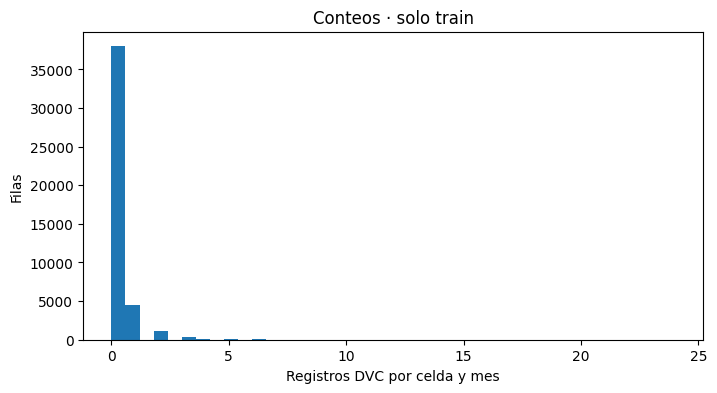

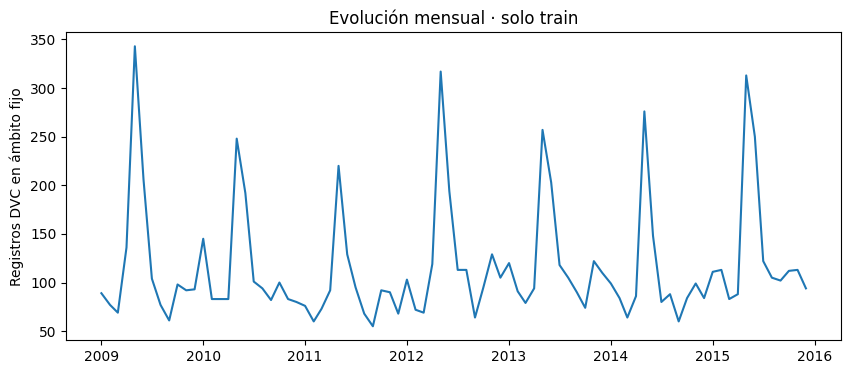

In [7]:
eda=df.loc[df['year']<=SUBTRAIN_END_YEAR]
display(eda['dvc_count'].describe())
display(eda.groupby('road_category')['dvc_count'].agg(['mean','std','median','count']))
plt.figure(figsize=(8,4)); plt.hist(eda['dvc_count'],bins=40)
plt.xlabel('Registros DVC por celda y mes'); plt.ylabel('Filas'); plt.title('Conteos · solo train'); plt.show()
count_by_date=eda.groupby('Date')['dvc_count'].sum()
plt.figure(figsize=(10,4)); plt.plot(count_by_date.index,count_by_date.values)
plt.ylabel('Registros DVC en ámbito fijo'); plt.title('Evolución mensual · solo train'); plt.show()

## 0.7 Partición maestra temporal

Se sustituye el 70/15/15 aleatorio del ejemplo de aguacates por el protocolo del
proyecto: **2009–2015 → 2016 → 2017**. Todas las tareas tabulares usan las mismas filas.
Los modelos se conservan ajustados con subtrain, sin un refit posterior a las decisiones,
para que las cuatro tareas sean comparables y reproducibles. Por ello sus métricas no
deben coincidir con las métricas publicadas por la web V11.

Este test mide generalización temporal en celdas conocidas, no transferencia a zonas nuevas.

In [8]:
idx_train=np.flatnonzero(df['year'].to_numpy()<=SUBTRAIN_END_YEAR)
idx_val=np.flatnonzero(df['year'].to_numpy()==VALIDATION_YEAR)
idx_test=np.flatnonzero(df['year'].to_numpy()==TEST_YEAR)
for name,ix in [('train',idx_train),('validation',idx_val),('test',idx_test)]:
    if not len(ix): raise ValueError(f'Partición vacía: {name}')
    if df.iloc[ix]['target_presence'].nunique()!=2: raise ValueError(f'{name} necesita ambas clases binarias.')
summary_split=pd.DataFrame([
    {'split':name,'n':len(ix),'inicio':df.iloc[ix]['Date'].min(),'fin':df.iloc[ix]['Date'].max()}
    for name,ix in [('train',idx_train),('validation',idx_val),('test',idx_test)]])
assert df.iloc[idx_train]['Date'].max()<df.iloc[idx_val]['Date'].min()<df.iloc[idx_test]['Date'].min()
assert not set(idx_train)&set(idx_val) and not set(idx_val)&set(idx_test)
display(summary_split)
print('TEST reservado para evaluación final de cada tarea, sin ajustar modelos después de verlo.')

,split,n,inicio,fin
0,train,44352,2009-01-01,2015-12-01
1,validation,6336,2016-01-01,2016-12-01
2,test,6336,2017-01-01,2017-12-01


TEST reservado para evaluación final de cada tarea, sin ajustar modelos después de verlo.


## 0.8 Targets sin fuga

**Regresión:** `dvc_count` en el mes objetivo.

**Binaria:** `target_presence = 1` si el conteo es positivo.

**Multiclase:** 0 = sin registros; 1 = conteo positivo moderado; 2 = conteo alto.
El corte entre 1 y 2 es el tercil superior de **conteos positivos de train**, redondeado
hacia arriba. Con muchos ceros, los terciles de todas las filas pueden coincidir en
cero y eliminar una clase: esta adaptación evita ese problema sin inventar diferencias.
Si el conjunto no contiene tres clases en train, se detiene esa tarea y explica por qué.

`dvc_count`, `target_presence` y sus derivados están prohibidos como entradas tabulares.

In [9]:
positive_train=df.iloc[idx_train].loc[lambda d:d['dvc_count']>0,'dvc_count']
q1=0
q2=int(max(1,np.ceil(positive_train.quantile(2/3))))
def count_class(values):
    values=np.asarray(values)
    return np.where(values<=0,0,np.where(values<=q2,1,2)).astype(int)
ypc_train=count_class(df.iloc[idx_train]['dvc_count'])
if len(np.unique(ypc_train))!=3:
    raise ValueError(f'No hay tres niveles distintos en train con corte {q2}; revisa la distribución de conteos.')
print('Corte fijado solo con train:',q2,'| 0=sin registros, 1=1..corte, 2=>corte')
display(pd.Series(ypc_train).value_counts().sort_index().rename('n_train'))

Corte fijado solo con train: 1 | 0=sin registros, 1=1..corte, 2=>corte


0    37984
1     4543
2     1825
Name: n_train, dtype: int64

# UNIDAD 1 · Basics of Neural Network

# 1.1 Understanding Perceptron

## Qué vamos a aprender
Un perceptrón calcula una combinación lineal de variables y aplica una función de activación:

\[
z = b + \sum_j w_j x_j
\]

\[
\hat y = f(z)
\]

Los pesos no son “importancias causales”: son parámetros que ayudan a construir una frontera de decisión.

## 1.1.A Puertas OR y AND: entender la frontera antes del dato real

In [10]:
def step01(z):
    return (np.asarray(z) >= 0).astype(int)

def perceptron_predict(X, w, b):
    return step01(np.asarray(X) @ np.asarray(w) + b)

X_logic=np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)

# OR: x1 + x2 - 0.5
y_or=perceptron_predict(X_logic,[1,1],-0.5)
# AND: x1 + x2 - 1.5
y_and=perceptron_predict(X_logic,[1,1],-1.5)

print(pd.DataFrame({'x1':X_logic[:,0],'x2':X_logic[:,1],'OR':y_or,'AND':y_and}))

    x1   x2  OR  AND
0  0.0  0.0   0    0
1  0.0  1.0   1    0
2  1.0  0.0   1    0
3  1.0  1.0   1    1


## 1.1.B Perceptrón sobre Roadkill en 2D

Con `log_traffic_mean` y `log_exposure_vkm_proxy` del **año previo** intentamos
separar meses con/sin registros DVC. Es una demostración geométrica; el target
no forma parte de las entradas. La imputación y el escalado aprenden solo de train.

In [11]:
from sklearn.linear_model import Perceptron
cols_2d=['log_traffic_mean','log_exposure_vkm_proxy']
X2_train=df.iloc[idx_train][cols_2d].to_numpy()
X2_val=df.iloc[idx_val][cols_2d].to_numpy()
y2_train=df.iloc[idx_train]['target_presence'].to_numpy()
y2_val=df.iloc[idx_val]['target_presence'].to_numpy()
sc2=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]).fit(X2_train)
X2_train_s=sc2.transform(X2_train); X2_val_s=sc2.transform(X2_val)
perc=Perceptron(random_state=SEED,max_iter=2000,tol=1e-4).fit(X2_train_s,y2_train)
print('Accuracy train:',accuracy_score(y2_train,perc.predict(X2_train_s)))
print('Accuracy validation:',accuracy_score(y2_val,perc.predict(X2_val_s)))
print('F1 validation:',f1_score(y2_val,perc.predict(X2_val_s),zero_division=0))
print('Pesos:',perc.coef_,'bias:',perc.intercept_)

Accuracy train: 0.6841630591630592
Accuracy validation: 0.6979166666666666
F1 validation: 0.45126146788990823
Pesos: [[2.23402371 0.14150745]] bias: [-1.]


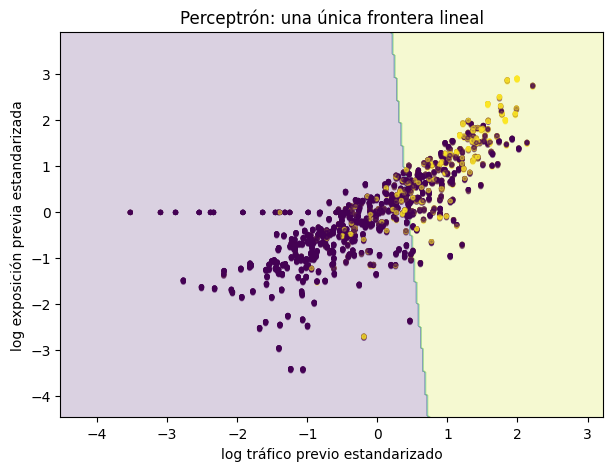

In [12]:
# Frontera lineal en validation
x_min,x_max=X2_val_s[:,0].min()-1,X2_val_s[:,0].max()+1
y_min,y_max=X2_val_s[:,1].min()-1,X2_val_s[:,1].max()+1
xx,yy=np.meshgrid(np.linspace(x_min,x_max,250),np.linspace(y_min,y_max,250))
zz=perc.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7,5))
plt.contourf(xx,yy,zz,alpha=.2)
plt.scatter(X2_val_s[:,0],X2_val_s[:,1],c=y2_val,s=8,alpha=.5)
plt.xlabel('log tráfico previo estandarizado')
plt.ylabel('log exposición previa estandarizada')
plt.title('Perceptrón: una única frontera lineal')
plt.show()

### Interpretación
Una única frontera lineal puede ser insuficiente. Además, una accuracy alta puede
proceder de acertar muchos ceros. La F1, el recall y las curvas Precision–Recall ayudan
a comprobar la utilidad para presencia DVC. Los pesos no demuestran causalidad.

# 1.2 Understanding Multilayer Perceptron

## 1.2.A XOR: el problema que un único perceptrón no puede resolver

XOR no es linealmente separable. La capa oculta transforma el espacio para que la salida pueda separarlo.

    x1   x2  XOR
0  0.0  0.0    0
1  0.0  1.0    1
2  1.0  0.0    1
3  1.0  1.0    0


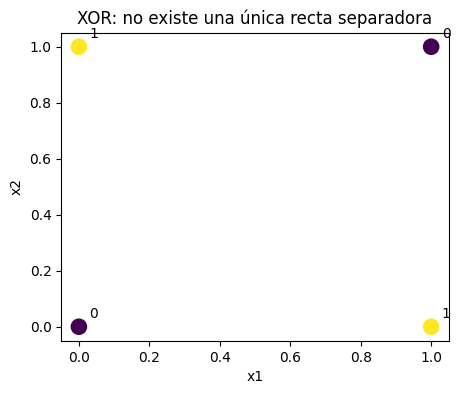

In [13]:
X_xor=np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_xor=np.array([0,1,1,0])

print(pd.DataFrame({'x1':X_xor[:,0],'x2':X_xor[:,1],'XOR':y_xor}))

plt.figure(figsize=(5,4))
plt.scatter(X_xor[:,0],X_xor[:,1],c=y_xor,s=120)
for x,y,l in zip(X_xor[:,0],X_xor[:,1],y_xor):
    plt.text(x+.03,y+.03,str(l))
plt.title('XOR: no existe una única recta separadora')
plt.xlabel('x1'); plt.ylabel('x2'); plt.show()

## 1.2.B MLP para XOR con Keras

Este bloque se ejecuta si TensorFlow está disponible. La finalidad es demostrar que una capa oculta puede aprender una representación no lineal.

In [14]:
if tf is not None:
    xor_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(2,)), tf.keras.layers.Dense(4, activation='tanh'), tf.keras.layers.Dense(1, activation='sigmoid')])
    xor_model.compile(optimizer=tf.keras.optimizers.Adam(0.03), loss='binary_crossentropy', metrics=['accuracy'])
    xor_model.fit(dataset_tf(X_xor, y_xor, training=True, batch=64), epochs=epochs(600), verbose=0)
    print(np.c_[X_xor, xor_model.predict(dataset_tf(X_xor), verbose=0).ravel()])
else:
    print('Instala TensorFlow para ejecutar esta celda.')

[[0.00000000e+00 0.00000000e+00 1.72646920e-04]
 [0.00000000e+00 1.00000000e+00 9.96446669e-01]
 [1.00000000e+00 0.00000000e+00 9.98422801e-01]
 [1.00000000e+00 1.00000000e+00 3.40641569e-03]]


# 1.3 From Multilayer Perceptron to Deep Learning

## 1.3.A Forward propagation manual con un registro real de Roadkill

Antes de utilizar `Dense`, calculamos a mano exactamente la misma idea:

\[
h = ReLU(W_1x+b_1), \quad \hat y = W_2h+b_2
\]

Usaremos dos variables escaladas de una observación real.

In [15]:
sample=sc2.transform(df.iloc[[idx_train[0]]][cols_2d].to_numpy())[0]
W1=np.array([[0.8,-0.4,0.5],[-0.3,0.9,0.2]])
b1=np.array([0.1,-0.2,0.05])
W2=np.array([[0.7],[-0.5],[0.4]])
b2=np.array([0.02])

z1=sample@W1+b1
h1=np.maximum(0,z1)
z2=h1@W2+b2
sigmoid=lambda z:1/(1+np.exp(-z))
yhat=sigmoid(z2)

print('x =',sample)
print('z1 =',z1)
print('ReLU(z1) =',h1)
print('z2 =',z2)
print('sigmoid(z2) =',yhat)

x = [-1.42312838 -2.47218958]
z1 = [-0.29684583 -1.85571927 -1.15600211]
ReLU(z1) = [0. 0. 0.]
z2 = [0.02]
sigmoid(z2) = [0.50499983]


### Qué representa cada número
- `x`: variables de entrada.
- `W`: pesos entrenables.
- `b`: bias entrenable.
- `z`: combinación lineal.
- activación: introduce no linealidad.
- `ŷ`: salida.

Una DNN repite este patrón muchas veces. **Profundidad no significa magia: significa composición de transformaciones.**

# 1.4 Error Backpropagation and Gradient Descent

## 1.4.A Loss y actualización
Para regresión podemos usar MSE:

\[
L=\frac{1}{n}\sum_i(y_i-\hat y_i)^2
\]

Gradient descent actualiza:

\[
\theta \leftarrow \theta-\eta\nabla_\theta L
\]

## 1.4.B Comprobación de gradiente: derivada analítica vs diferencia finita

In [16]:
# y_hat = w*x + b para un ejemplo sencillo
x=2.0; y=3.0; w=0.4; b=0.1

def loss_w(w_):
    yhat=w_*x+b
    return (y-yhat)**2

# d/dw (y-(wx+b))^2 = -2*x*(y-yhat)
yhat=w*x+b
grad_analytic=-2*x*(y-yhat)

eps=1e-6
grad_numeric=(loss_w(w+eps)-loss_w(w-eps))/(2*eps)
print('Gradiente analítico:',grad_analytic)
print('Gradiente numérico :',grad_numeric)
print('Diferencia:',abs(grad_analytic-grad_numeric))

Gradiente analítico: -8.4
Gradiente numérico : -8.399999999575414
Diferencia: 4.2458658811028727e-10


## 1.4.C Descenso de gradiente manual: tráfico previo → conteo DVC

w: 0.19697358716708216 b: 0.21985479797979798 MSE final train: 0.472871780003449


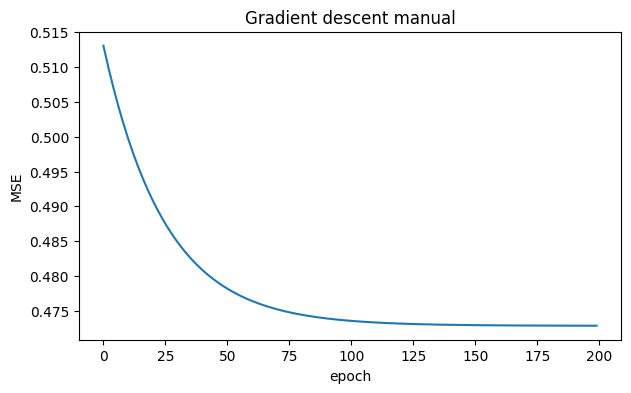

In [17]:
xgd=X2_train_s[:,0].astype(float)
ygd=df.iloc[idx_train]['dvc_count'].to_numpy(dtype=float)
# Escalado manual usando SOLO train
xm, xs=xgd.mean(), xgd.std()
xn=(xgd-xm)/xs
w=0.0; b=ygd.mean(); lr=0.01
history_gd=[]
for epoch in range(200):
    pred=w*xn+b
    err=pred-ygd
    loss=np.mean(err**2)
    dw=2*np.mean(err*xn)
    db=2*np.mean(err)
    w-=lr*dw; b-=lr*db
    history_gd.append(loss)

print('w:',w,'b:',b,'MSE final train:',history_gd[-1])
plt.figure(figsize=(7,4)); plt.plot(history_gd); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.title('Gradient descent manual'); plt.show()

# 1.5 Activation Functions

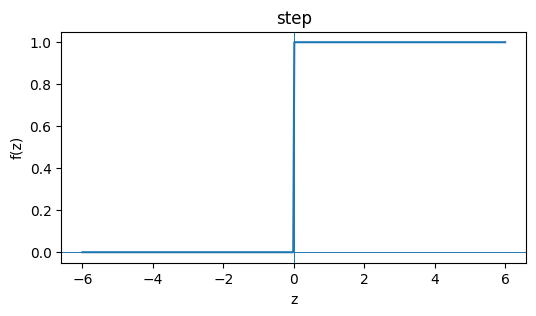

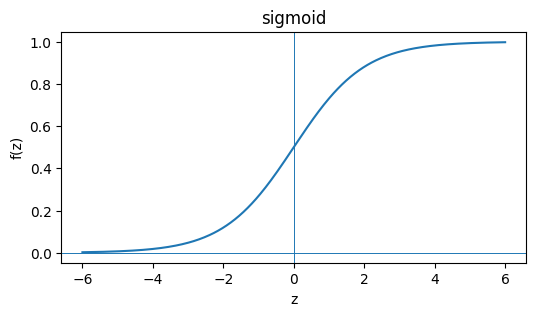

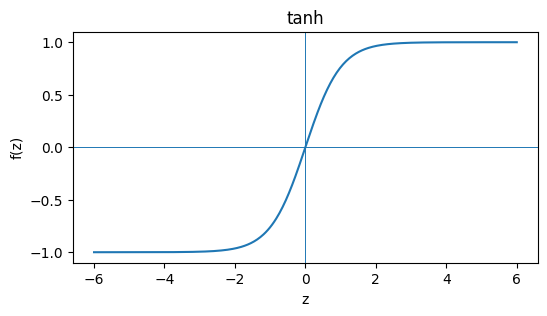

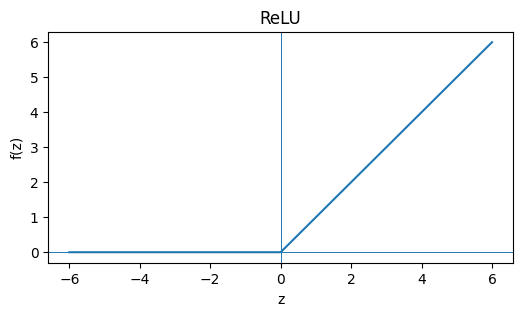

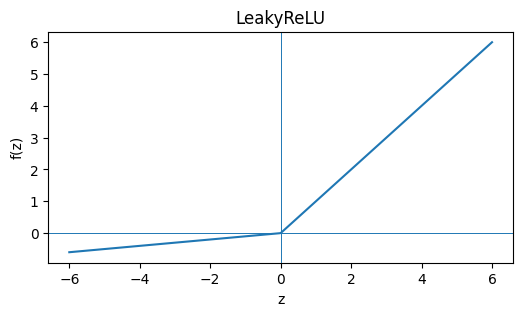

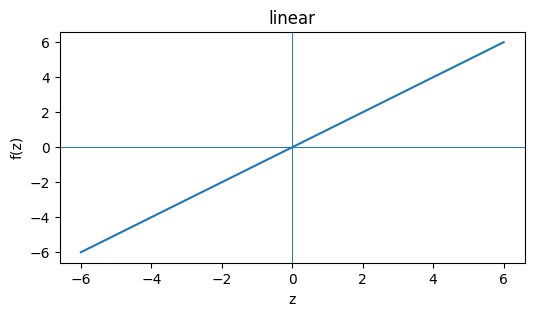

In [18]:
z=np.linspace(-6,6,400)
activations={
    'step':(z>=0).astype(float),
    'sigmoid':1/(1+np.exp(-z)),
    'tanh':np.tanh(z),
    'ReLU':np.maximum(0,z),
    'LeakyReLU':np.where(z>=0,z,0.1*z),
    'linear':z,
}
for name,a in activations.items():
    plt.figure(figsize=(6,3))
    plt.plot(z,a)
    plt.axhline(0,linewidth=.7); plt.axvline(0,linewidth=.7)
    plt.title(name); plt.xlabel('z'); plt.ylabel('f(z)'); plt.show()

## 1.5.B Elección según salida

| Tarea | Activación | Loss |
|---|---|---|
| Conteo DVC, demostración de regresión | linear | MSE |
| Presencia DVC | sigmoid | binary crossentropy |
| Sin registros / moderado / alto | softmax | sparse categorical crossentropy |
| Capas ocultas | ReLU o variantes | — |

La salida lineal puede ser negativa. Para contar eventos se aplica `max(0, predicción)`
al evaluar **todos** los regresores. Como referencia apropiada para conteos incluimos
Poisson con salida positiva. Las salidas neuronales son estimaciones, no probabilidades
calibradas de sufrir un accidente individual.


## 1.5.C Softmax explícita

Convierte tres logits en probabilidades que suman uno. Se resta el máximo para
evitar desbordamiento. Los números son una demostración matemática, no un pronóstico.


In [19]:

logits_demo=np.array([1.,2.,-.5])
exp_demo=np.exp(logits_demo-logits_demo.max())
softmax_demo=exp_demo/exp_demo.sum()
print('Probabilidades:',softmax_demo,'| suma:',softmax_demo.sum())
assert np.isclose(softmax_demo.sum(),1)


Probabilidades: [0.25371618 0.68967209 0.05661173] | suma: 1.0000000000000002


# 1.6 Deep Learning

## ¿Más profundidad = mejor?
No. Vamos a comparar arquitecturas **solo en validation**. La comparación definitiva con baselines se hará en U3.

In [20]:
# Funciones auxiliares que se utilizarán más adelante
if tf is not None:
    def build_binary_mlp(n_features, hidden=(32,), dropout=0.0, l2=0.0, lr=1e-3):
        reg=tf.keras.regularizers.l2(l2) if l2>0 else None
        layers=[tf.keras.layers.Input(shape=(n_features,))]
        for units in hidden:
            layers.append(tf.keras.layers.Dense(units,activation='relu',kernel_regularizer=reg))
            if dropout>0: layers.append(tf.keras.layers.Dropout(dropout))
        layers.append(tf.keras.layers.Dense(1,activation='sigmoid'))
        m=tf.keras.Sequential(layers)
        m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss='binary_crossentropy',metrics=['accuracy'])
        return m
else:
    print('Definiremos los modelos al instalar TensorFlow.')

# 1.7 Problems of Deep Learning and the Solutions

## 1.7.A Vanishing gradient
Con Sigmoid/Tanh saturadas, derivadas pequeñas pueden reducir el gradiente a medida que retrocede por muchas capas. ReLU y buenas inicializaciones ayudaron históricamente a entrenar redes profundas.

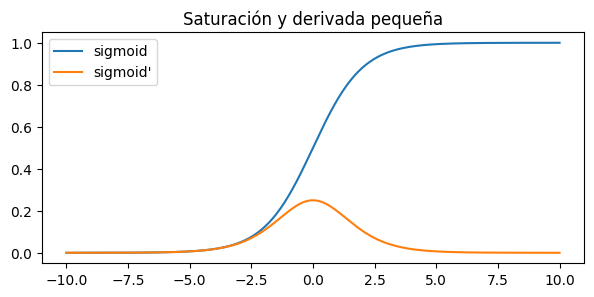

In [21]:
z=np.linspace(-10,10,500)
sig=1/(1+np.exp(-z)); dsig=sig*(1-sig)
plt.figure(figsize=(7,3)); plt.plot(z,sig,label='sigmoid'); plt.plot(z,dsig,label="sigmoid'"); plt.legend(); plt.title('Saturación y derivada pequeña'); plt.show()

## 1.7.B Overfitting y soluciones

Síntoma típico:
- train loss sigue bajando;
- validation loss deja de bajar y empieza a subir.

Herramientas:
- L2,
- Dropout,
- EarlyStopping,
- reducir capacidad,
- más datos,
- mejor validación.

> La regularización no sirve para “subir accuracy” de forma automática; sirve para favorecer generalización.

## ✅ Checklist U1
Antes de seguir, debes poder explicar:
- qué calculan pesos y bias;
- por qué XOR necesita una transformación no lineal;
- qué es forward propagation;
- qué mide una loss;
- qué hace backpropagation;
- por qué el gradiente modifica pesos;
- para qué sirven ReLU, Sigmoid, Linear y Softmax;
- por qué una red profunda puede sobreajustar;
- y por qué **más capas no implican una mejora demostrada**.

# UNIDAD 2 · Basics of TensorFlow

# 2.1 Introduction to TensorFlow

TensorFlow representa datos y operaciones mediante tensores. En TensorFlow 2, eager execution permite trabajar de forma cercana a NumPy, mientras que `tf.function` puede construir grafos optimizados cuando interesa.

In [22]:
if tf is not None:
    real_matrix=np.c_[X2_train_s[:5], df.iloc[idx_train[:5]]['year'].to_numpy()].astype('float32')
    t=tf.convert_to_tensor(real_matrix)
    print(t)
    print('rank:',tf.rank(t).numpy(),'shape:',t.shape,'dtype:',t.dtype)
else:
    print('Instala TensorFlow.')

tf.Tensor(
[[-1.4231284e+00 -2.4721897e+00  2.0090000e+03]
 [-7.2479421e-01 -6.2090158e-01  2.0090000e+03]
 [-1.0094174e+00 -6.7617512e-01  2.0090000e+03]
 [-6.4278919e-01 -1.0220487e+00  2.0090000e+03]
 [ 1.4872876e-01  1.8909521e-01  2.0090000e+03]], shape=(5, 3), dtype=float32)
rank: 2 shape: (5, 3) dtype: <dtype: 'float32'>


## 2.1.B Tensor = valores + shape + dtype

In [23]:
if tf is not None:
    scalar=tf.constant(1.33)
    vector=tf.constant([1.1,1.2,1.3])
    matrix=tf.constant([[1.,2.],[3.,4.]])
    cube=tf.ones((2,3,4))
    for name,obj in [('scalar',scalar),('vector',vector),('matrix',matrix),('rank3',cube)]:
        print(name,'rank=',tf.rank(obj).numpy(),'shape=',obj.shape)

scalar rank= 0 shape= ()
vector rank= 1 shape= (3,)
matrix rank= 2 shape= (2, 2)
rank3 rank= 3 shape= (2, 3, 4)


## 2.1.C `constant` vs `Variable`

In [24]:
if tf is not None:
    c=tf.constant(2.0)
    w=tf.Variable(2.0)
    print('constant:',c)
    print('variable:',w)
    w.assign_sub(0.25)
    print('variable actualizada:',w)

constant: tf.Tensor(2.0, shape=(), dtype=float32)
variable: <tf.Variable 'Variable:0' shape=() dtype=float32, numpy=2.0>
variable actualizada: <tf.Variable 'Variable:0' shape=() dtype=float32, numpy=1.75>


## 2.1.D Cast, transpose, reshape y squeeze

In [25]:
if tf is not None:
    a=tf.range(12)
    b=tf.reshape(a,(3,4))
    print('reshape:\n',b.numpy())
    print('transpose:\n',tf.transpose(b).numpy())
    print('cast dtype:',tf.cast(b,tf.float32).dtype)
    print('squeeze:',tf.squeeze(tf.zeros((1,3,1))).shape)

reshape:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
transpose:
 [[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]]
cast dtype: <dtype: 'float32'>
squeeze: (3,)


## 2.1.E Operaciones matemáticas

In [26]:
if tf is not None:
    A=tf.constant([[1.,2.],[3.,4.]])
    B=tf.constant([[2.,0.],[1.,2.]])
    print('multiply elemento a elemento:\n',tf.multiply(A,B).numpy())
    print('matmul:\n',tf.linalg.matmul(A,B).numpy())
    print('mean:',tf.reduce_mean(A).numpy())
    print('norm:',tf.linalg.norm(A).numpy())

multiply elemento a elemento:
 [[2. 0.]
 [3. 8.]]
matmul:
 [[ 4.  4.]
 [10.  8.]]
mean: 2.5
norm: 5.477226


## 2.1.F `GradientTape`: backpropagation automático

In [27]:
if tf is not None:
    w=tf.Variable(0.4,dtype=tf.float32)
    x=tf.constant(2.0); y=tf.constant(3.0); b=tf.constant(0.1)
    with tf.GradientTape() as tape:
        pred=w*x+b
        loss=tf.square(y-pred)
    grad=tape.gradient(loss,w)
    print('loss:',loss.numpy(),'gradient:',grad.numpy())
    print('Comparar con la derivada analítica de U1.4.')

loss: 4.4099994 gradient: -8.4
Comparar con la derivada analítica de U1.4.


# 2.2 TensorFlow Dataset

`tf.data` separa la lógica de alimentación de datos del modelo. Esto permite barajar, agrupar en batches, transformar y prefetch de forma reproducible.

In [28]:
num_cols=log_cols+['year','month_sin','month_cos','easting_mean','northing_mean']
num_pipeline=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                       ('scale',StandardScaler())])
X_num_train=df.iloc[idx_train][num_cols].to_numpy(dtype=np.float32)
X_num_val=df.iloc[idx_val][num_cols].to_numpy(dtype=np.float32)
y_count_train=df.iloc[idx_train]['dvc_count'].to_numpy(dtype=np.float32)
y_count_val=df.iloc[idx_val]['dvc_count'].to_numpy(dtype=np.float32)
X_num_train_s=num_pipeline.fit_transform(X_num_train).astype('float32')
X_num_val_s=num_pipeline.transform(X_num_val).astype('float32')
assert np.isfinite(X_num_train_s).all() and np.isfinite(X_num_val_s).all()
ds=tf.data.Dataset.from_tensor_slices((X_num_train_s,y_count_train))
print(ds.element_spec)
for xb,yb in ds.take(1):print('x shape:',xb.shape,'y:',yb.numpy())

(TensorSpec(shape=(10,), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.float32, name=None))
x shape: (10,) y: 0.0


## 2.2.B `shuffle()`, `batch()` y `repeat()`

In [29]:
if tf is not None:
    demo=tf.data.Dataset.from_tensor_slices(np.arange(8))
    print('Original :',list(demo.as_numpy_iterator()))
    print('Shuffle  :',list(demo.shuffle(8,seed=SEED,reshuffle_each_iteration=False).as_numpy_iterator()))
    print('Batches  :',[x.tolist() for x in demo.batch(3).as_numpy_iterator()])
    print('Repeat x2:',list(demo.repeat(2).as_numpy_iterator()))

Original : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
Shuffle  : [np.int64(1), np.int64(2), np.int64(6), np.int64(7), np.int64(4), np.int64(0), np.int64(3), np.int64(5)]
Batches  : [[0, 1, 2], [3, 4, 5], [6, 7]]
Repeat x2: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


### Por qué importa el orden
`shuffle().batch()` mezcla observaciones antes de agruparlas. `batch().shuffle()` baraja grupos ya formados. No son operaciones equivalentes.

## 2.2.C Normalización sin fuga dentro del pipeline

La imputación por mediana y `StandardScaler` se ajustan únicamente con train.
Validation/test reutilizan los parámetros. Las variables de calendario no requieren
ajuste estadístico; las transformaciones `log1p` también son deterministas.

## 2.2.D `cache()` y `prefetch()`

In [30]:
BATCH=64
def dataset_tf(X,y=None,training=False,batch=BATCH):
    ds=tf.data.Dataset.from_tensor_slices(X if y is None else (X,y))
    # map se ejecuta antes de cache; shuffle después de cache cambia el orden cada epoch.
    if y is not None:
        ds=ds.map(lambda x,t:(tf.cast(x,tf.float32),tf.cast(t,tf.float32)))
    else: ds=ds.map(lambda x:tf.cast(x,tf.float32))
    ds=ds.cache()
    if training: ds=ds.shuffle(len(X),seed=SEED,reshuffle_each_iteration=True)
    options=tf.data.Options()
    options.threading.private_threadpool_size=2
    return ds.batch(batch).with_options(options).prefetch(1)
train_ds=dataset_tf(X_num_train_s,y_count_train,training=True)
val_ds=dataset_tf(X_num_val_s,y_count_val)
print(train_ds.element_spec)

(TensorSpec(shape=(None, 10), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))



## Experimento 0.B · Medición de la generalización sobre ruido

Partición aleatoria exclusivamente en este experimento sintético independiente.
La frecuencia mayoritaria se aprende con train; train/validation/test de Roadkill
no intervienen. Una ganancia puntual en test no crea una relación real entre X e y.


In [31]:

ir=np.arange(len(demo_random))
ir_train,ir_tmp=train_test_split(ir,test_size=.3,random_state=SEED,stratify=demo_random['clase_aleatoria'])
ir_val,ir_test=train_test_split(ir_tmp,test_size=.5,random_state=SEED,stratify=demo_random.iloc[ir_tmp]['clase_aleatoria'])
random_scale=StandardScaler().fit(demo_random.iloc[ir_train,:-1])
RX=random_scale.transform(demo_random.iloc[:,:-1]).astype('float32')
Ry=demo_random['clase_aleatoria'].to_numpy()
random_dummy=DummyClassifier(strategy='most_frequent').fit(RX[ir_train],Ry[ir_train])
random_logit=LogisticRegression(max_iter=1000).fit(RX[ir_train],Ry[ir_train])
random_mlp=tf.keras.Sequential([tf.keras.layers.Input((RX.shape[1],)),
    tf.keras.layers.Dense(128,activation='relu'),tf.keras.layers.Dense(64,activation='relu'),
    tf.keras.layers.Dense(5,activation='softmax')])
random_mlp.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
random_h=random_mlp.fit(dataset_tf(RX[ir_train],Ry[ir_train],True),
    validation_data=dataset_tf(RX[ir_val],Ry[ir_val]),epochs=epochs(60),verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=8,restore_best_weights=True)])
random_rows=[]
for name,model in [('Mayoritaria',random_dummy),('Logistic',random_logit),('MLP',random_mlp)]:
    pred_tr=model.predict(RX[ir_train]) if name!='MLP' else model.predict(dataset_tf(RX[ir_train]),verbose=0).argmax(1)
    pred_te=model.predict(RX[ir_test]) if name!='MLP' else model.predict(dataset_tf(RX[ir_test]),verbose=0).argmax(1)
    random_rows.append([name,accuracy_score(Ry[ir_train],pred_tr),accuracy_score(Ry[ir_test],pred_te)])
display(pd.DataFrame(random_rows,columns=['modelo','accuracy_train','accuracy_test']))


,modelo,accuracy_train,accuracy_test
0,Mayoritaria,0.308571,0.313333
1,Logistic,0.314286,0.286667
2,MLP,0.314286,0.266667


# 2.3 Machine Learning with TensorFlow

## 2.3.A Regresión lineal de bajo nivel

MSE train final: 0.4474407136440277


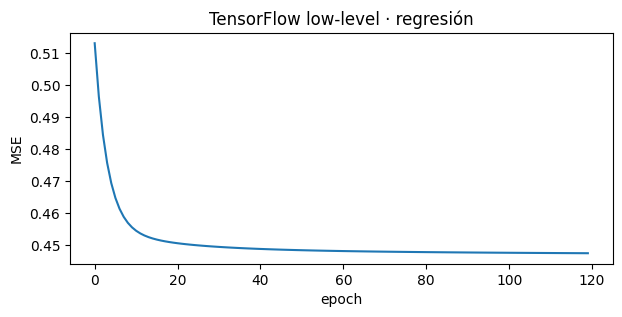

In [32]:
if tf is not None:
    Xtf=tf.constant(X_num_train_s)
    ytf=tf.constant(y_count_train.reshape(-1,1))
    W=tf.Variable(tf.zeros((X_num_train_s.shape[1],1)))
    b=tf.Variable([[float(y_count_train.mean())]])
    opt=tf.keras.optimizers.SGD(learning_rate=0.02)
    losses=[]
    for epoch in range(120):
        with tf.GradientTape() as tape:
            pred=tf.matmul(Xtf,W)+b
            loss=tf.reduce_mean(tf.square(ytf-pred))
        grads=tape.gradient(loss,[W,b])
        opt.apply_gradients(zip(grads,[W,b]))
        losses.append(float(loss))
    print('MSE train final:',losses[-1])
    plt.figure(figsize=(7,3)); plt.plot(losses); plt.title('TensorFlow low-level · regresión'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.show()

## 2.3.B Clasificación binaria de bajo nivel

In [33]:
if tf is not None:
    y_type_train=df.iloc[idx_train]['target_presence'].astype('float32').to_numpy().reshape(-1,1)
    Xtf=tf.constant(X_num_train_s)
    ytf=tf.constant(y_type_train)
    Wc=tf.Variable(tf.zeros((X_num_train_s.shape[1],1)))
    bc=tf.Variable([[0.0]])
    opt=tf.keras.optimizers.Adam(0.02)
    for epoch in range(100):
        with tf.GradientTape() as tape:
            logits=tf.matmul(Xtf,Wc)+bc
            loss=tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=ytf,logits=logits))
        grads=tape.gradient(loss,[Wc,bc])
        opt.apply_gradients(zip(grads,[Wc,bc]))
    probs=tf.sigmoid(tf.matmul(tf.constant(X_num_val_s),Wc)+bc).numpy().ravel()
    pred=(probs>=.5).astype(int)
    yv=df.iloc[idx_val]['target_presence'].astype(int).to_numpy()
    print('Validation accuracy:',accuracy_score(yv,pred),'F1:',f1_score(yv,pred))

Validation accuracy: 0.851010101010101 F1: 0.30280649926144754


## 2.3.C Losses y optimizers

| Tarea | Salida | Loss |
|---|---|---|
| Conteos (regresión didáctica) | linear | MSE / MAE |
| Presencia DVC | sigmoid | binary crossentropy |
| Intensidad en tres clases | softmax | sparse categorical crossentropy |

En el modelo Poisson, la función de enlace impone medias positivas.
Adam optimiza parámetros; no garantiza que una arquitectura sea adecuada.

## ✅ Checklist U2
Debes poder explicar:
- tensor, rank, shape y dtype;
- diferencia entre `constant` y `Variable`;
- por qué `matmul` aparece en una capa Dense;
- qué hace `GradientTape`;
- por qué `tf.data` no es “el modelo”;
- por qué normalizar con todo el dataset sería fuga;
- y cómo una regresión/logística básica puede programarse sin Keras.

# UNIDAD 3 · Deep Learning Methods with TensorFlow and Keras

# 3.1 Main Features of TensorFlow

In [34]:
if tf is not None:
    print('TensorFlow:',tf.__version__)
    print('Dispositivos físicos:',tf.config.list_physical_devices())
    print('GPUs:',tf.config.list_physical_devices('GPU'))
    print('Eager:',tf.executing_eagerly())

TensorFlow: 2.21.0
Dispositivos físicos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPUs: []
Eager: True


TensorFlow incluye capas, losses, optimizers, `tf.data`, autodiferenciación, guardado, distribución y utilidades hardware. Keras proporciona la API de alto nivel para expresar el modelo con menos código.

# 3.2 Keras Basics

## Flujo Keras

`Input → Dense → ... → Output`  
`compile()` define loss/optimizer/metrics.  
`fit()` ejecuta el entrenamiento.  
`evaluate()` calcula métricas.  
`predict()` genera salidas.

In [35]:
if tf is not None:
    demo_model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_num_train_s.shape[1],)),
        tf.keras.layers.Dense(16,activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    demo_model.compile(optimizer='adam',loss='mse',metrics=['mae'])
    demo_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

## 3.2.B Callback opcional: ver el entrenamiento epoch a epoch

In [36]:
LIVE_TRAINING_PLOTS = False

if tf is not None:
    from IPython.display import clear_output
    class LiveHistory(tf.keras.callbacks.Callback):
        def on_train_begin(self, logs=None):
            self.losses=[]; self.val_losses=[]
        def on_epoch_end(self, epoch, logs=None):
            self.losses.append(logs.get('loss'))
            self.val_losses.append(logs.get('val_loss'))
            if LIVE_TRAINING_PLOTS:
                clear_output(wait=True)
                plt.figure(figsize=(7,3))
                plt.plot(self.losses,label='train')
                plt.plot(self.val_losses,label='validation')
                plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.show()

# 3.3 AI with Keras

## 3.3.A Preprocesamiento tabular completo

Entradas: tráfico y red del año anterior, proxy de exposición, coordenadas, año y
calendario, más `road_category` y `local_authority_name` codificadas con one-hot.
Se mantiene el mismo preprocesamiento para regresión, multiclase y binaria.
Ninguna entrada contiene el conteo/presencia del mes objetivo ni predicciones de la web.

In [37]:
num_reg=num_cols
cat_reg=cat_cols
features_reg=num_reg+cat_reg
assert not {'dvc_count','target_presence','p_final','pred_count_final'} & set(features_reg)
X_reg=df[features_reg]
y_reg=df['dvc_count'].to_numpy()
def make_preprocessor():
    return ColumnTransformer([
        ('num',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                         ('scale',StandardScaler())]),num_reg),
        ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_reg)
    ])
prep_reg=make_preprocessor()
Xr_train=prep_reg.fit_transform(X_reg.iloc[idx_train]).astype('float32')
Xr_val=prep_reg.transform(X_reg.iloc[idx_val]).astype('float32')
Xr_test=prep_reg.transform(X_reg.iloc[idx_test]).astype('float32')
yr_train=y_reg[idx_train].astype('float32'); yr_val=y_reg[idx_val].astype('float32'); yr_test=y_reg[idx_test].astype('float32')
for matrix in [Xr_train,Xr_val,Xr_test]:assert np.isfinite(matrix).all()
def clip_count(pred): return np.maximum(0,np.asarray(pred).ravel())
print(Xr_train.shape,Xr_val.shape,Xr_test.shape)

(44352, 47) (6336, 47) (6336, 47)


## 3.3.B Regresión de conteos: media → Ridge / Poisson → red lineal → MLP

### MUST aplicado
Antes de entrenar una MLP definimos referencias más simples:
1. baseline que predice la media de train;
2. Ridge;
3. una red de una sola capa lineal;
4. MLP.

La elección de arquitectura se hace con **validation**. Test se toca al final del bloque.

In [38]:
val_mean_pred=np.full(len(yr_val),yr_train.mean())
ridge=Ridge(alpha=1.).fit(Xr_train,yr_train)
poisson=PoissonRegressor(alpha=1.,max_iter=1000).fit(Xr_train,yr_train)
reg_classic={'Media':lambda X:np.full(len(X),yr_train.mean()),
             'Ridge':ridge.predict,'Poisson':poisson.predict}
reg_val_scores={name:mean_absolute_error(yr_val,clip_count(fn(Xr_val))) for name,fn in reg_classic.items()}
baseline_reg_selected=min(reg_val_scores,key=reg_val_scores.get)
display(pd.Series(reg_val_scores,name='MAE_validation'))
print('Referencia congelada con validation:',baseline_reg_selected)

Media      0.415282
Ridge      0.337638
Poisson    0.375382
Name: MAE_validation, dtype: float64

Referencia congelada con validation: Ridge


In [39]:
if tf is not None:

    def build_regression(n_features, hidden=(), dropout=0.0, l2=0.0, lr=0.001):
        reg = tf.keras.regularizers.l2(l2) if l2 > 0 else None
        layers = [tf.keras.layers.Input(shape=(n_features,))]
        for u in hidden:
            layers.append(tf.keras.layers.Dense(u, activation='relu', kernel_regularizer=reg))
            if dropout > 0:
                layers.append(tf.keras.layers.Dropout(dropout))
        layers.append(tf.keras.layers.Dense(1, activation='linear'))
        m = tf.keras.Sequential(layers)
        m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])
        return m
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.5, min_lr=1e-05)]
    reg_linear = build_regression(Xr_train.shape[1], hidden=())
    h_lin = reg_linear.fit(dataset_tf(Xr_train, yr_train, training=True, batch=64), validation_data=dataset_tf(Xr_val, yr_val), epochs=epochs(150), verbose=0, callbacks=callbacks)
    reg_mlp = build_regression(Xr_train.shape[1], hidden=(64, 32), dropout=0.1, l2=1e-05)
    h_mlp = reg_mlp.fit(dataset_tf(Xr_train, yr_train, training=True, batch=64), validation_data=dataset_tf(Xr_val, yr_val), epochs=epochs(200), verbose=0, callbacks=callbacks + [LiveHistory()])
    pred_lin_val = reg_linear.predict(dataset_tf(Xr_val), verbose=0).ravel()
    pred_mlp_val = reg_mlp.predict(dataset_tf(Xr_val), verbose=0).ravel()
    print('Keras lineal VAL MAE:', mean_absolute_error(yr_val, pred_lin_val))
    print('MLP VAL MAE:', mean_absolute_error(yr_val, pred_mlp_val))

Keras lineal VAL MAE: 0.3616293668746948
MLP VAL MAE: 0.30017727613449097


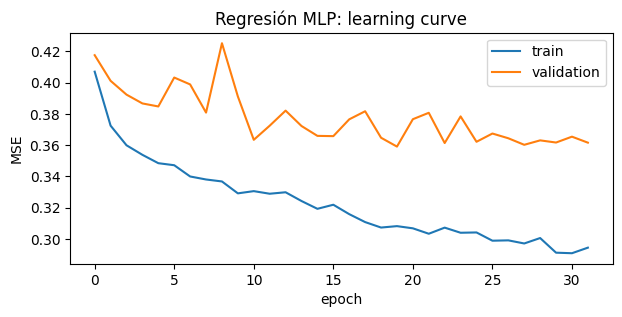

In [40]:
if tf is not None:
    plt.figure(figsize=(7,3)); plt.plot(h_mlp.history['loss'],label='train'); plt.plot(h_mlp.history['val_loss'],label='validation'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.title('Regresión MLP: learning curve'); plt.legend(); plt.show()

### Lectura
- Si MLP no mejora Ridge de forma relevante, **Ridge es una mejor respuesta al problema** por simplicidad.
- Si MLP mejora claramente validation y después mantiene la mejora en test, existe evidencia a favor de la no linealidad aprendida.

> El objetivo docente no es “hacer ganar” a Deep Learning. Es medirlo.

## 3.3.C Overfitting, L2 y Dropout sobre el mismo problema

VAL MAE por arquitectura: {'small': 0.33194562792778015, 'large': 0.29765957593917847, 'regularized': 0.3036026954650879}


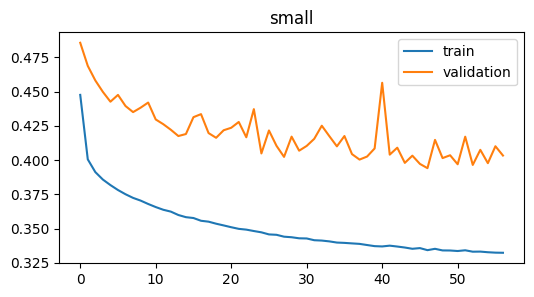

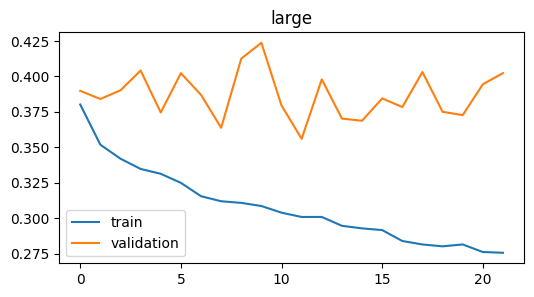

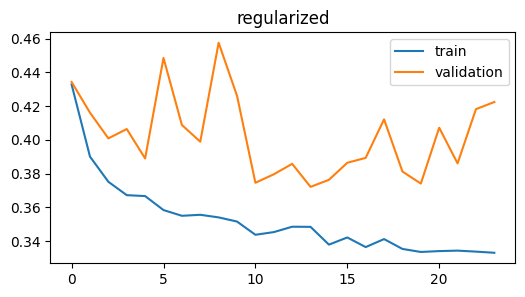

Red de regresión congelada: large {'MLP': 0.29859083890914917, 'small': 0.32352617383003235, 'large': 0.29690009355545044, 'regularized': 0.3020513653755188}


In [41]:
if tf is not None:
    candidates = {'small': build_regression(Xr_train.shape[1], hidden=(16,)), 'large': build_regression(Xr_train.shape[1], hidden=(256, 128, 64)), 'regularized': build_regression(Xr_train.shape[1], hidden=(128, 64), dropout=0.25, l2=0.0001)}
    val_results = {}
    histories = {}
    for name, m in candidates.items():
        h = m.fit(dataset_tf(Xr_train, yr_train, training=True, batch=64), validation_data=dataset_tf(Xr_val, yr_val), epochs=epochs(120), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
        histories[name] = h
        pv = m.predict(dataset_tf(Xr_val), verbose=0).ravel()
        val_results[name] = mean_absolute_error(yr_val, pv)
    print('VAL MAE por arquitectura:', val_results)
    for name, h in histories.items():
        plt.figure(figsize=(6, 3))
        plt.plot(h.history['loss'], label='train')
        plt.plot(h.history['val_loss'], label='validation')
        plt.title(name)
        plt.legend()
        plt.show()
    neural_reg_candidates = {'MLP': reg_mlp, **candidates}
    neural_reg_val = {name: mean_absolute_error(yr_val, clip_count(model.predict(Xr_val, verbose=0).ravel())) for name, model in neural_reg_candidates.items()}
    selected_reg_arch = min(neural_reg_val, key=neural_reg_val.get)
    reg_mlp = neural_reg_candidates[selected_reg_arch]
    print('Red de regresión congelada:', selected_reg_arch, neural_reg_val)

## 3.3.D Evaluación FINAL de regresión en test

In [42]:
regression_test_results = []
regression_predictions = {}
for name, fn in reg_classic.items():
    regression_predictions[name] = clip_count(fn(Xr_test))
regression_predictions['Keras lineal'] = clip_count(reg_linear.predict(dataset_tf(Xr_test), verbose=0))
regression_predictions['MLP'] = clip_count(reg_mlp.predict(dataset_tf(Xr_test), verbose=0))
for name, p in regression_predictions.items():
    regression_test_results.append([name, mean_absolute_error(yr_test, p), mean_squared_error(yr_test, p) ** 0.5, r2_score(yr_test, p)])
regression_test_df = pd.DataFrame(regression_test_results, columns=['modelo', 'MAE', 'RMSE', 'R2'])
display(regression_test_df.round(4))
print('evaluate de la red seleccionada (MSE/MAE sin recorte):', reg_mlp.evaluate(dataset_tf(Xr_test, yr_test), verbose=0, return_dict=True))

,modelo,MAE,RMSE,R2
0,Media,0.4399,0.8659,-0.0086
1,Ridge,0.3548,0.7350,0.2732
2,Poisson,0.3970,0.8030,0.1325
3,Keras lineal,0.3667,0.7390,0.2652
4,MLP,0.3231,0.6406,0.4479


evaluate de la red seleccionada (MSE/MAE sin recorte): {'loss': 0.41042962670326233, 'mae': 0.32401102781295776}


## 3.3.E Multiclase: SIN REGISTROS / MODERADO / ALTO

Las etiquetas derivan del conteo del mes objetivo, con el corte fijado en train.
`dvc_count` y `target_presence` no pueden entrar como predictores de esas clases.
Macro-F1 se calcula siempre sobre las tres clases, aunque alguna falte en validation/test.

In [43]:
features_count_cls=features_reg
y_pc=count_class(df['dvc_count'])
prep_pc=prep_reg
Xpc_train,Xpc_val,Xpc_test=Xr_train,Xr_val,Xr_test
ypc_train,ypc_val,ypc_test=y_pc[idx_train],y_pc[idx_val],y_pc[idx_test]
logit_multi=LogisticRegression(max_iter=3000).fit(Xpc_train,ypc_train)
dummy_multi=DummyClassifier(strategy='most_frequent').fit(Xpc_train,ypc_train)
multi_val_f1={name:f1_score(ypc_val,model.predict(Xpc_val),labels=[0,1,2],average='macro',zero_division=0)
              for name,model in [('Mayoritaria',dummy_multi),('Logistic',logit_multi)]}
baseline_multi_selected=max(multi_val_f1,key=multi_val_f1.get)
pred=logit_multi.predict(Xpc_val)
print('Logistic VAL accuracy:',accuracy_score(ypc_val,pred),'macro-F1:',
      f1_score(ypc_val,pred,labels=[0,1,2],average='macro',zero_division=0))

Logistic VAL accuracy: 0.8405934343434344 macro-F1: 0.4083399237148948


In [44]:
if tf is not None:
    multi_mlp = tf.keras.Sequential([tf.keras.layers.Input(shape=(Xpc_train.shape[1],)), tf.keras.layers.Dense(96, activation='relu'), tf.keras.layers.Dropout(0.2), tf.keras.layers.Dense(48, activation='relu'), tf.keras.layers.Dense(3, activation='softmax')])
    multi_mlp.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h_multi = multi_mlp.fit(dataset_tf(Xpc_train, ypc_train, training=True, batch=64), validation_data=dataset_tf(Xpc_val, ypc_val), epochs=epochs(150), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)])
    prob_val = multi_mlp.predict(dataset_tf(Xpc_val), verbose=0)
    pred_val = prob_val.argmax(axis=1)
    print('MLP VAL accuracy:', accuracy_score(ypc_val, pred_val), 'macro-F1:', f1_score(ypc_val, pred_val, average='macro'))

MLP VAL accuracy: 0.8469065656565656 macro-F1: 0.46575996866247266


### Evaluación final multiclase en test

In [45]:
multi_test_rows = []
for name, p in [('Mayoritaria', dummy_multi.predict(Xpc_test)), ('Logistic', logit_multi.predict(Xpc_test)), ('MLP softmax', multi_mlp.predict(dataset_tf(Xpc_test), verbose=0).argmax(axis=1))]:
    multi_test_rows.append([name, accuracy_score(ypc_test, p), f1_score(ypc_test, p, labels=[0, 1, 2], average='macro', zero_division=0)])
    print(name)
    print(classification_report(ypc_test, p, labels=[0, 1, 2], target_names=['SIN REGISTROS', 'MODERADO', 'ALTO'], zero_division=0))
    print(confusion_matrix(ypc_test, p, labels=[0, 1, 2]))
multi_test_df = pd.DataFrame(multi_test_rows, columns=['modelo', 'accuracy', 'macro_f1'])
display(multi_test_df.round(4))

Mayoritaria
               precision    recall  f1-score   support

SIN REGISTROS       0.82      1.00      0.90      5188
     MODERADO       0.00      0.00      0.00       774
         ALTO       0.00      0.00      0.00       374

     accuracy                           0.82      6336
    macro avg       0.27      0.33      0.30      6336
 weighted avg       0.67      0.82      0.74      6336

[[5188    0    0]
 [ 774    0    0]
 [ 374    0    0]]
Logistic
               precision    recall  f1-score   support

SIN REGISTROS       0.83      1.00      0.91      5188
     MODERADO       0.52      0.01      0.03       774
         ALTO       0.67      0.20      0.31       374

     accuracy                           0.83      6336
    macro avg       0.67      0.40      0.42      6336
 weighted avg       0.79      0.83      0.77      6336

[[5172    1   15]
 [ 740   11   23]
 [ 289    9   76]]
MLP softmax
               precision    recall  f1-score   support

SIN REGISTROS       0.85 

,modelo,accuracy,macro_f1
0,Mayoritaria,0.8188,0.3001
1,Logistic,0.8300,0.4158
2,MLP softmax,0.8365,0.4724


## 3.3.F Clasificación binaria: presencia DVC en el mes objetivo

Logistic Regression, Random Forest y MLP usan exactamente las mismas variables y
particiones. El conteo del mes objetivo está prohibido como entrada, porque define
directamente la etiqueta de presencia. El baseline de prevalencia constante muestra
cuánto aportan las variables frente a predecir la frecuencia media de train.

El bosque añade una referencia no lineal fuerte: ganar a Logistic por sí solo no
demuestra que una red sea la mejor alternativa disponible.

In [46]:
prep_type=prep_reg
Xt_train,Xt_val,Xt_test=Xr_train,Xr_val,Xr_test
yt=df['target_presence'].to_numpy()
yt_train,yt_val,yt_test=yt[idx_train],yt[idx_val],yt[idx_test]
logit_type=LogisticRegression(max_iter=3000).fit(Xt_train,yt_train)
rf_type=RandomForestClassifier(n_estimators=200,min_samples_leaf=10,max_features='sqrt',
                               n_jobs=2,random_state=SEED).fit(Xt_train,yt_train)
prob_log_val=logit_type.predict_proba(Xt_val)[:,1]
prob_rf_val=rf_type.predict_proba(Xt_val)[:,1]
print('Logistic VAL ROC-AUC:',roc_auc_score(yt_val,prob_log_val),'AP:',average_precision_score(yt_val,prob_log_val))
print('RandomForest VAL AP:',average_precision_score(yt_val,prob_rf_val))
print('AP es average precision; no se usa el área trapezoidal de la curva PR.')

Logistic VAL ROC-AUC: 0.8231562448307793 AP: 0.5280107832629582
RandomForest VAL AP: 0.5824654451586853
AP es average precision; no se usa el área trapezoidal de la curva PR.


In [47]:
if tf is not None:
    type_mlp = build_binary_mlp(Xt_train.shape[1], hidden=(64, 32), dropout=0.15, l2=1e-05)
    h_type = type_mlp.fit(dataset_tf(Xt_train, yt_train, training=True, batch=64), validation_data=dataset_tf(Xt_val, yt_val), epochs=epochs(150), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
    prob_type_val = type_mlp.predict(dataset_tf(Xt_val), verbose=0).ravel()
    print('MLP VAL AUC:', roc_auc_score(yt_val, prob_type_val), 'AP:', average_precision_score(yt_val, prob_type_val))

MLP VAL AUC: 0.8507484807531601 AP: 0.5806149491748336


### 3.3.F.1 Selección de umbral **solo en validation**
0.5 no es una ley. Elegiremos el umbral que maximiza F1 en validation y después lo congelaremos para test.

In [48]:
def best_f1_threshold(y_true,prob):
    thresholds=np.linspace(.01,.99,199)
    scores=[f1_score(y_true,(prob>=t).astype(int),zero_division=0) for t in thresholds]
    i=int(np.argmax(scores))
    return float(thresholds[i]),float(scores[i])
thr_log,f1_log=best_f1_threshold(yt_val,prob_log_val)
thr_rf,f1_rf=best_f1_threshold(yt_val,prob_rf_val)
thr_mlp,f1_mlp=best_f1_threshold(yt_val,prob_type_val)
bin_val_f1={'Logistic':f1_log,'RandomForest':f1_rf}
baseline_bin_selected=max(bin_val_f1,key=bin_val_f1.get)
binary_thresholds={'Logistic':thr_log,'RandomForest':thr_rf,'MLP':thr_mlp,'Prevalencia':.5}
display(pd.DataFrame({'umbral':binary_thresholds,'F1_val':{**bin_val_f1,'MLP':f1_mlp}}))
print('Referencia binaria congelada con validation:',baseline_bin_selected)

,umbral,F1_val
Logistic,0.262424,0.515568
RandomForest,0.282222,0.546624
MLP,0.282222,0.542553
Prevalencia,0.500000,NaN


Referencia binaria congelada con validation: RandomForest


### 3.3.F.2 ROC y Precision–Recall en validation

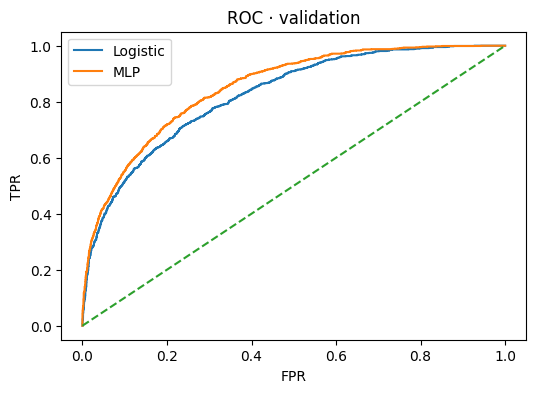

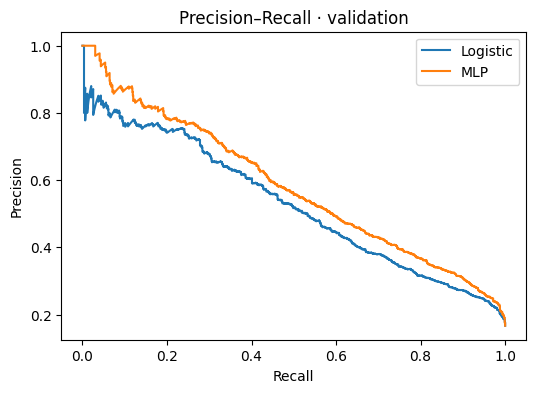

In [49]:
plt.figure(figsize=(6,4))
fpr,tpr,_=roc_curve(yt_val,prob_log_val); plt.plot(fpr,tpr,label='Logistic')
if tf is not None:
    fpr,tpr,_=roc_curve(yt_val,prob_type_val); plt.plot(fpr,tpr,label='MLP')
plt.plot([0,1],[0,1],'--'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC · validation'); plt.legend(); plt.show()

plt.figure(figsize=(6,4))
p,r,_=precision_recall_curve(yt_val,prob_log_val); plt.plot(r,p,label='Logistic')
if tf is not None:
    p,r,_=precision_recall_curve(yt_val,prob_type_val); plt.plot(r,p,label='MLP')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision–Recall · validation'); plt.legend(); plt.show()

### 3.3.F.3 Evaluación FINAL binaria en test

In [50]:
binary_probs = {'Prevalencia': np.full(len(yt_test), yt_train.mean()), 'Logistic': logit_type.predict_proba(Xt_test)[:, 1], 'RandomForest': rf_type.predict_proba(Xt_test)[:, 1], 'MLP': type_mlp.predict(dataset_tf(Xt_test), verbose=0).ravel()}
binary_test_rows = []
for name, prob in binary_probs.items():
    pred = (prob >= binary_thresholds[name]).astype(int)
    binary_test_rows.append([name, accuracy_score(yt_test, pred), precision_score(yt_test, pred, zero_division=0), recall_score(yt_test, pred, zero_division=0), f1_score(yt_test, pred, zero_division=0), roc_auc_score(yt_test, prob), average_precision_score(yt_test, prob), brier_score_loss(yt_test, prob), int(pred.sum())])
binary_test_df = pd.DataFrame(binary_test_rows, columns=['modelo', 'accuracy', 'precision', 'recall', 'F1', 'ROC_AUC', 'AP', 'Brier', 'alertas'])
display(binary_test_df.round(4))
for name in ['Logistic', 'RandomForest', 'MLP']:
    pred = (binary_probs[name] >= binary_thresholds[name]).astype(int)
    print(name, classification_report(yt_test, pred, labels=[0, 1], target_names=['SIN REGISTROS', 'CON REGISTROS'], zero_division=0))
    print(confusion_matrix(yt_test, pred, labels=[0, 1]))

,modelo,accuracy,precision,recall,F1,ROC_AUC,AP,Brier,alertas
0,Prevalencia,0.8188,0.0000,0.0000,0.0000,0.5000,0.1812,0.1498,0
1,Logistic,0.8253,0.5174,0.5305,0.5239,0.8249,0.5623,0.1130,1177
2,RandomForest,0.8422,0.5674,0.5427,0.5548,0.8440,0.6007,0.1073,1098
3,MLP,0.8291,0.5252,0.5906,0.5560,0.8441,0.6026,0.1055,1291


Logistic                precision    recall  f1-score   support

SIN REGISTROS       0.90      0.89      0.89      5188
CON REGISTROS       0.52      0.53      0.52      1148

     accuracy                           0.83      6336
    macro avg       0.71      0.71      0.71      6336
 weighted avg       0.83      0.83      0.83      6336

[[4620  568]
 [ 539  609]]
RandomForest                precision    recall  f1-score   support

SIN REGISTROS       0.90      0.91      0.90      5188
CON REGISTROS       0.57      0.54      0.55      1148

     accuracy                           0.84      6336
    macro avg       0.73      0.73      0.73      6336
 weighted avg       0.84      0.84      0.84      6336

[[4713  475]
 [ 525  623]]
MLP                precision    recall  f1-score   support

SIN REGISTROS       0.91      0.88      0.89      5188
CON REGISTROS       0.53      0.59      0.56      1148

     accuracy                           0.83      6336
    macro avg       0.72      0.

## 3.3.G Frontera neuronal dinámica en 2D (opcional)

Con tráfico y exposición del año previo podemos dibujar cómo cambia la frontera.
`LIVE_BOUNDARY=True` activa el gráfico durante el entrenamiento; no modifica la
partición ni el objetivo. Esta prueba sirve para visualizar, no para elegir por test.

In [51]:
LIVE_BOUNDARY = False
if tf is not None:
    from IPython.display import clear_output
    model2d = build_binary_mlp(2, hidden=(16, 16), lr=0.01)

    class BoundaryCallback(tf.keras.callbacks.Callback):

        def on_epoch_end(self, epoch, logs=None):
            if not LIVE_BOUNDARY or epoch % 2:
                return
            clear_output(wait=True)
            gx, gy = np.meshgrid(np.linspace(X2_train_s[:, 0].min() - 1, X2_train_s[:, 0].max() + 1, 180), np.linspace(X2_train_s[:, 1].min() - 1, X2_train_s[:, 1].max() + 1, 180))
            grid = np.c_[gx.ravel(), gy.ravel()]
            z = self.model.predict(grid, verbose=0).reshape(gx.shape)
            plt.figure(figsize=(6, 5))
            plt.contourf(gx, gy, z, levels=np.linspace(0, 1, 11), alpha=0.3)
            plt.scatter(X2_val_s[:, 0], X2_val_s[:, 1], c=y2_val, s=7, alpha=0.45)
            plt.title(f"Epoch {epoch + 1} · val_loss={logs.get('val_loss'):.3f}")
            plt.show()
    model2d.fit(dataset_tf(X2_train_s, y2_train, training=True, batch=64), validation_data=dataset_tf(X2_val_s, y2_val), epochs=epochs(30), verbose=0, callbacks=[BoundaryCallback()])
    print('Pon LIVE_BOUNDARY=True para visualizar el aprendizaje.')

Pon LIVE_BOUNDARY=True para visualizar el aprendizaje.


# 3.3.H Series temporales · pronóstico con LSTM

## Pronóstico mensual con pasado → futuro

La serie suma los eventos DVC de las celdas fijadas con AADF 2008, sin escoger la
zona de mayor siniestralidad de test. Incluye todos los meses entre enero de 2008 y
diciembre de 2017. Si falta un mes de observación, rellenar con cero sería una
hipótesis de cobertura, no un hecho probado: se conserva esa limitación.

Ventana de 12 meses para predecir el siguiente. Train termina en 2015; validation
es 2016; test es 2017. La media y desviación se estiman solo hasta 2015.
Se evalúa **un mes por delante con observaciones reales disponibles**: la ventana
de febrero de 2017 puede usar enero de 2017 ya observado. No es un pronóstico
recursivo de todo 2017 hecho desde diciembre de 2016.

Serie mensual en ámbito fijo: 120 meses; 528 celdas


,Date,dvc_count
0,2008-01-01,46
1,2008-02-01,53
2,2008-03-01,58
3,2008-04-01,53
4,2008-05-01,208


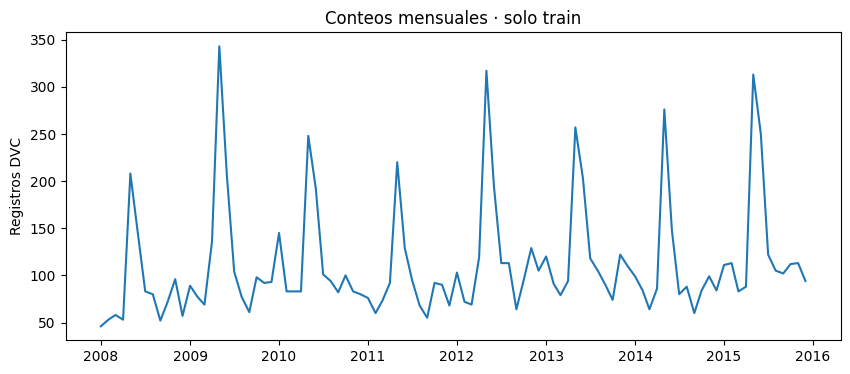

In [52]:
monthly_index=pd.date_range('2008-01-01','2017-12-01',freq='MS')
fixed_dvc=dvc_valid.loc[dvc_valid['cell'].isin(study_cells)].copy()
fixed_dvc['Date']=pd.to_datetime(dict(year=fixed_dvc['year'],month=fixed_dvc['month'],day=1))
ts=(fixed_dvc.groupby('Date').size().reindex(monthly_index,fill_value=0)
    .rename('dvc_count').rename_axis('Date').reset_index())
print('Serie mensual en ámbito fijo:',len(ts),'meses;',len(study_cells),'celdas')
display(ts.head())
plt.figure(figsize=(10,4)); past=ts['Date'].dt.year<=2015
plt.plot(ts.loc[past,'Date'],ts.loc[past,'dvc_count'])
plt.title('Conteos mensuales · solo train'); plt.ylabel('Registros DVC'); plt.show()

## 3.3.H.1 Construcción de ventanas sin mirar el futuro

In [53]:
WINDOW=12
values=ts['dvc_count'].to_numpy(dtype='float32')
dates=ts['Date'].to_numpy()
train_raw=values[ts['Date'].dt.year.to_numpy()<=2015]
mean_ts=float(train_raw.mean()); std_ts=float(train_raw.std())
if std_ts<=0:raise ValueError('La serie de train es constante; no permite este experimento.')
scaled=(values-mean_ts)/std_ts
def make_windows(arr,window=12):
    idx=np.arange(window,len(arr))
    return np.stack([arr[i-window:i] for i in idx]).astype('float32'),arr[idx].astype('float32'),idx
Xseq,yseq,iseq=make_windows(scaled,WINDOW)
target_years=ts['Date'].iloc[iseq].dt.year.to_numpy()
mask_train=target_years<=2015; mask_val=target_years==2016; mask_test=target_years==2017
Xs_train,yseq_train=Xseq[mask_train],yseq[mask_train]
Xs_val,yseq_val=Xseq[mask_val],yseq[mask_val]
Xs_test,yseq_test=Xseq[mask_test],yseq[mask_test]
assert mask_train.sum()>WINDOW and mask_val.sum()==12 and mask_test.sum()==12
for i in iseq: assert dates[i-1]<dates[i]
print('Ventanas train/validation/test:',Xs_train.shape,Xs_val.shape,Xs_test.shape)
def inverse_ts(pred):return clip_count(np.asarray(pred)*std_ts+mean_ts)

Ventanas train/validation/test: (84, 12) (12, 12) (12, 12)


## 3.3.H.2 Baseline naïve: “la próxima mes será como la última”

In [54]:
naive_val=Xs_val[:,-1]
seasonal_val=Xs_val[:,0] # mismo mes del año anterior con ventana de 12 meses
print('Persistencia VAL MAE:',mean_absolute_error(inverse_ts(yseq_val),inverse_ts(naive_val)))
print('Estacional VAL MAE:',mean_absolute_error(inverse_ts(yseq_val),inverse_ts(seasonal_val)))

Persistencia VAL MAE: 53.25
Estacional VAL MAE: 20.25


## 3.3.H.3 Baseline Ridge sobre la ventana

In [55]:
ridge_ts=Ridge(alpha=1.0).fit(Xs_train,yseq_train)
pr=ridge_ts.predict(Xs_val)
print('Ridge VAL MAE:',mean_absolute_error(yseq_val*std_ts+mean_ts,pr*std_ts+mean_ts))

Ridge VAL MAE: 29.29252815246582


## 3.3.H.4 MLP sobre la ventana

In [56]:
if tf is not None:
    mlp_ts = tf.keras.Sequential([tf.keras.layers.Input(shape=(WINDOW,)), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dense(1)])
    mlp_ts.compile(optimizer='adam', loss='mse', metrics=['mae'])
    mlp_ts.fit(dataset_tf(Xs_train, yseq_train, training=True, batch=64), validation_data=dataset_tf(Xs_val, yseq_val), epochs=epochs(200), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)])
    p = mlp_ts.predict(dataset_tf(Xs_val), verbose=0).ravel()
    print('MLP VAL MAE:', mean_absolute_error(yseq_val * std_ts + mean_ts, p * std_ts + mean_ts))

MLP VAL MAE: 31.03948211669922


## 3.3.H.5 LSTM: arquitectura secuencial

In [57]:
if tf is not None:
    Xl_train = Xs_train[..., None]
    Xl_val = Xs_val[..., None]
    Xl_test = Xs_test[..., None]
    lstm = tf.keras.Sequential([tf.keras.layers.Input(shape=(WINDOW, 1)), tf.keras.layers.LSTM(32), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dense(1)])
    lstm.compile(optimizer='adam', loss='mse', metrics=['mae'])
    h_lstm = lstm.fit(dataset_tf(Xl_train, yseq_train, training=True, batch=16), validation_data=dataset_tf(Xl_val, yseq_val), epochs=epochs(250), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)])
    p = lstm.predict(dataset_tf(Xl_val), verbose=0).ravel()
    print('LSTM VAL MAE:', mean_absolute_error(yseq_val * std_ts + mean_ts, p * std_ts + mean_ts))

LSTM VAL MAE: 28.49042320251465


### Comparación antes de abrir test temporal

Se comparan persistencia, mismo mes del año anterior, Ridge, MLP y LSTM en validation.
La referencia clásica se selecciona **antes de conocer 2017**. La LSTM se mantiene
como arquitectura secuencial a contrastar, sin cambiarla según el resultado de test.
Con solo 12 meses de test, una diferencia de MAE no demuestra por sí sola una mejora estable.

## 3.3.H.6 Evaluación temporal FINAL en test

In [58]:
ts_val_predictions = {'Naive': inverse_ts(Xs_val[:, -1]), 'Estacional': inverse_ts(Xs_val[:, 0]), 'Ridge-window': inverse_ts(ridge_ts.predict(Xs_val)), 'MLP-window': inverse_ts(mlp_ts.predict(dataset_tf(Xs_val), verbose=0).ravel()), 'LSTM': inverse_ts(lstm.predict(dataset_tf(Xl_val), verbose=0).ravel())}
ts_val_mae = {name: mean_absolute_error(inverse_ts(yseq_val), p) for name, p in ts_val_predictions.items()}
baseline_ts_selected = min(['Naive', 'Estacional', 'Ridge-window'], key=ts_val_mae.get)
print('VAL MAE:', ts_val_mae, '| referencia congelada:', baseline_ts_selected)
ytrue = inverse_ts(yseq_test)
ts_test_predictions = {'Naive': inverse_ts(Xs_test[:, -1]), 'Estacional': inverse_ts(Xs_test[:, 0]), 'Ridge-window': inverse_ts(ridge_ts.predict(Xs_test)), 'MLP-window': inverse_ts(mlp_ts.predict(dataset_tf(Xs_test), verbose=0).ravel()), 'LSTM': inverse_ts(lstm.predict(dataset_tf(Xl_test), verbose=0).ravel())}
p_lstm = ts_test_predictions['LSTM']
ts_test_rows = [[name, mean_absolute_error(ytrue, p), mean_squared_error(ytrue, p) ** 0.5] for name, p in ts_test_predictions.items()]
ts_test_df = pd.DataFrame(ts_test_rows, columns=['modelo', 'MAE', 'RMSE'])
display(ts_test_df.round(4))

VAL MAE: {'Naive': 53.25, 'Estacional': 20.25, 'Ridge-window': 29.29252815246582, 'MLP-window': 31.03948211669922, 'LSTM': 28.49042320251465} | referencia congelada: Estacional


,modelo,MAE,RMSE
0,Naive,58.8333,89.4381
1,Estacional,26.8333,32.3651
2,Ridge-window,41.9821,49.3024
3,MLP-window,34.9772,45.6165
4,LSTM,47.7931,65.1952


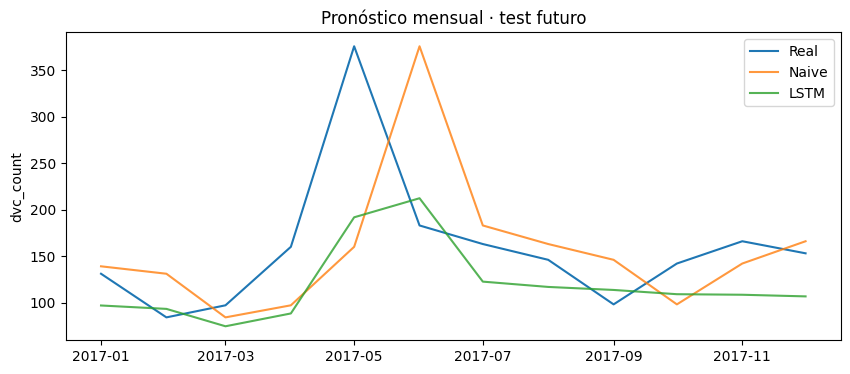

In [59]:
# Visualización de test temporal
idx_dates=iseq[mask_test]
plt.figure(figsize=(10,4))
plt.plot(ts['Date'].iloc[idx_dates],ytrue,label='Real')
plt.plot(ts['Date'].iloc[idx_dates],ts_test_predictions['Naive'],label='Naive',alpha=.8)
if tf is not None:
    plt.plot(ts['Date'].iloc[idx_dates],p_lstm,label='LSTM',alpha=.8)
plt.title('Pronóstico mensual · test futuro')
plt.ylabel('dvc_count'); plt.legend(); plt.show()

# 3.3.I MUST GATE · ¿Cuándo mejora realmente la red neuronal?

Esta sección es el corazón del reto.

No preguntamos “¿qué accuracy tiene la red?”. Preguntamos:

1. ¿qué baseline había que superar?
2. ¿la comparación usa el mismo test?
3. ¿la métrica responde al problema?
4. ¿la mejora es material o marginal?
5. ¿el coste de complejidad compensa?

### Regla
**Si una red no mejora de forma relevante, la conclusión correcta puede ser elegir el modelo clásico.** Eso no es un fracaso del ejercicio; es una conclusión científica.

In [60]:
must_rows=[]
def must_row(task,table,baseline,neural,metric,lower,required):
    b=float(table.set_index('modelo').loc[baseline,metric])
    n=float(table.set_index('modelo').loc[neural,metric])
    gain=b-n if lower else n-b
    assessed=gain/max(abs(b),1e-12) if lower else gain
    return [task,baseline,b,neural,n,gain,assessed,required,assessed>=required]
must_rows.append(must_row('Conteo DVC',regression_test_df,baseline_reg_selected,'MLP','MAE',True,MIN_REL_MAE_GAIN))
must_rows.append(must_row('Intensidad DVC',multi_test_df,baseline_multi_selected,'MLP softmax','macro_f1',False,MIN_F1_GAIN))
must_rows.append(must_row('Presencia DVC',binary_test_df,baseline_bin_selected,'MLP','F1',False,MIN_F1_GAIN))
must_rows.append(must_row('Pronóstico mensual',ts_test_df,baseline_ts_selected,'LSTM','MAE',True,MIN_REL_MAE_GAIN))
must_df=pd.DataFrame(must_rows,columns=['tarea','baseline_val','baseline_test','red','red_test',
    'ganancia_absoluta','ganancia_evaluada','mínimo_exploratorio','supera_mínimo'])
display(must_df.round(4))
for _,row in must_df.iterrows():
    verdict='supera el criterio exploratorio' if row['supera_mínimo'] else 'no demuestra la mejora mínima fijada'
    print(f"{row['tarea']}: {row['red']} {verdict} frente a {row['baseline_val']}.")
print('En MAE se exige reducción relativa del 5%; en F1/macro-F1, +0.01 absoluto.')
print('Estos límites son pedagógicos: no prueban significación estadística ni ahorro económico.')
if QUICK_RUN: print('MODO BREVE: no interpretar como resultado final de aprendizaje.')

,tarea,baseline_val,baseline_test,red,red_test,ganancia_absoluta,ganancia_evaluada,mínimo_exploratorio,supera_mínimo
0,Conteo DVC,Ridge,0.3548,MLP,0.3231,0.0318,0.0896,0.05,True
1,Intensidad DVC,Logistic,0.4158,MLP softmax,0.4724,0.0566,0.0566,0.01,True
2,Presencia DVC,RandomForest,0.5548,MLP,0.5560,0.0012,0.0012,0.01,False
3,Pronóstico mensual,Estacional,26.8333,LSTM,47.7931,-20.9598,-0.7811,0.05,False


Conteo DVC: MLP supera el criterio exploratorio frente a Ridge.
Intensidad DVC: MLP softmax supera el criterio exploratorio frente a Logistic.
Presencia DVC: MLP no demuestra la mejora mínima fijada frente a RandomForest.
Pronóstico mensual: LSTM no demuestra la mejora mínima fijada frente a Estacional.
En MAE se exige reducción relativa del 5%; en F1/macro-F1, +0.01 absoluto.
Estos límites son pedagógicos: no prueban significación estadística ni ahorro económico.


## 3.3.J ¿Y las CNN?
El Chapter 8 también introduce convoluciones. Este dataset tabular no tiene estructura espacial 2D como una imagen, por lo que **no es correcto forzar una `Conv2D` solo para poder decir que se ha usado una CNN**.

En la serie temporal podría estudiarse una `Conv1D` porque sí existe una estructura local ordenada en el tiempo. Se deja como ampliación opcional.

> Aprender Deep Learning incluye aprender **cuándo NO usar una arquitectura**.

# 3.3.K Guardado, trazabilidad y auditoría

In [61]:
OUTDIR = RAIZ / 'artifacts/reto08_capitulo8_completo'
OUTDIR.mkdir(parents=True, exist_ok=True)
tables = {'metricas_regresion': regression_test_df, 'metricas_multiclase': multi_test_df, 'metricas_binaria': binary_test_df, 'metricas_serie_temporal': ts_test_df, 'MUST_comparacion_red_vs_baseline': must_df, 'particiones': summary_split}
for name, table in tables.items():
    table.to_csv(OUTDIR / (name + '.csv'), index=False)
test_export = df.iloc[idx_test][['cell', 'year', 'month', 'road_category', 'local_authority_name', 'dvc_count', 'target_presence']].copy()
test_export['pred_count_mlp'] = regression_predictions['MLP']
test_export['residual_count'] = yr_test - test_export['pred_count_mlp'].to_numpy()
for name, prob in binary_probs.items():
    test_export['p_' + name.lower()] = prob
test_export['class_true'] = ypc_test
test_export['class_mlp'] = multi_mlp.predict(dataset_tf(Xpc_test), verbose=0).argmax(axis=1)
test_export.to_csv(OUTDIR / 'predicciones_test_2017_cap8.csv', index=False)
temporal_export = pd.DataFrame({'Date': ts['Date'].iloc[iseq[mask_test]].to_numpy(), 'count_real': ytrue})
for name, p in ts_test_predictions.items():
    temporal_export[name] = p
temporal_export.to_csv(OUTDIR / 'predicciones_mensuales_test_2017.csv', index=False)
for name, model in [('roadkill_count_mlp', reg_mlp), ('roadkill_count_linear', reg_linear), ('roadkill_multiclass_mlp', multi_mlp), ('roadkill_presence_mlp', type_mlp), ('roadkill_monthly_mlp', mlp_ts), ('roadkill_monthly_lstm', lstm)]:
    model.save(OUTDIR / (name + '.keras'))
joblib.dump({'preprocessor': prep_reg, 'ridge': ridge, 'poisson': poisson, 'logistic_binary': logit_type, 'rf_binary': rf_type, 'logistic_multi': logit_multi, 'ridge_window': ridge_ts, 'features': features_reg, 'study_cells': study_cells, 'binary_thresholds': binary_thresholds, 'class_cut': q2, 'ts_mean': mean_ts, 'ts_std': std_ts, 'window': WINDOW}, OUTDIR / 'preprocesamiento_y_baselines.joblib')

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()
config = {'seed': SEED, 'quick_run': QUICK_RUN, 'data_source': DATA_SOURCE, 'audit': audit_input, 'source_sha256': {Path(p).name: sha256_file(p) for p in [AADF_CSV, dvc_file] if Path(p).is_file()}, 'features': features_reg, 'annual_features_lag_years': 1, 'train': '2009-2015', 'validation': 2016, 'test': 2017, 'refit_after_validation': False, 'n_train': len(idx_train), 'n_validation': len(idx_val), 'n_test': len(idx_test), 'class_rule': {'zero': 0, 'positive_upper_cut': q2}, 'binary_thresholds': binary_thresholds, 'selected_reg_arch': selected_reg_arch, 'baseline_selection_on_validation': {'regression': baseline_reg_selected, 'binary': baseline_bin_selected, 'multiclass': baseline_multi_selected, 'temporal': baseline_ts_selected}, 'time_series': {'window': WINDOW, 'mean_train': mean_ts, 'std_train': std_ts, 'protocol': 'rolling_one_step'}, 'exploratory_gate': {'relative_MAE_gain': MIN_REL_MAE_GAIN, 'absolute_F1_gain': MIN_F1_GAIN}, 'versions': {'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': mdpkg.version('scikit-learn'), 'tensorflow': tf.__version__}, 'must_rule': 'Demostrar mejora frente a baseline con selección en validation y test temporal.'}
(OUTDIR / 'configuracion.json').write_text(json.dumps(config, indent=2, default=lambda o: int(o) if isinstance(o, np.integer) else str(o)), encoding='utf-8')
print('Resultados, modelos y preprocesamiento exportados en:', OUTDIR.resolve())
print(sorted((p.name for p in OUTDIR.iterdir())))

Resultados, modelos y preprocesamiento exportados en: C:\Users\Gabriel\Documents\GitHub\IA\artifacts\reto08_capitulo8_completo
['MUST_comparacion_red_vs_baseline.csv', 'configuracion.json', 'metricas_binaria.csv', 'metricas_multiclase.csv', 'metricas_regresion.csv', 'metricas_serie_temporal.csv', 'particiones.csv', 'predicciones_mensuales_test_2017.csv', 'predicciones_test_2017_cap8.csv', 'preprocesamiento_y_baselines.joblib', 'roadkill_count_linear.keras', 'roadkill_count_mlp.keras', 'roadkill_monthly_lstm.keras', 'roadkill_monthly_mlp.keras', 'roadkill_multiclass_mlp.keras', 'roadkill_presence_mlp.keras']


# ✅ Cierre completo U1 + U2 + U3

Al terminar este notebook, el alumno debería poder defender oralmente:

1. por qué las etiquetas aleatorias no contienen señal;
2. qué diferencia un perceptrón de una MLP;
3. qué hacen pesos, bias y activaciones;
4. cómo se relacionan forward, loss, backpropagation y optimizer;
5. por qué train, validation y test tienen funciones distintas;
6. qué es un tensor y cómo `tf.data` alimenta una red;
7. qué hacen `compile`, `fit`, `evaluate` y `predict`;
8. cómo se construye una regresión, una clasificación binaria y una multiclase;
9. cómo se detecta y combate overfitting;
10. por qué una LSTM requiere validación temporal;
11. por qué no debemos forzar CNN/LSTM donde la estructura del dato no lo justifica;
12. y, por encima de todo:

> # **MUST · HAY QUE DEMOSTRAR CUÁNDO UNA RED NEURONAL MEJORA EL PROBLEMA.**

Una red neuronal es una hipótesis de modelado, no una garantía de superioridad.

# Preguntas finales

1. ¿Por qué una etiqueta independiente de las variables no contiene señal?
2. ¿Qué aprende un peso y por qué no demuestra causalidad?
3. ¿Por qué XOR necesita una transformación no lineal?
4. ¿Cómo se relacionan `GradientTape` y backpropagation?
5. ¿Qué fuga introduce ajustar la imputación/escalado con todo el panel?
6. ¿Por qué el conteo objetivo no puede entrar en la clasificación de intensidad?
7. ¿Por qué tampoco puede entrar en la clasificación binaria de presencia?
8. ¿Por qué puede ser útil conocer el conteo del mes anterior para una serie temporal?
9. ¿Por qué macro-F1 y AP aportan información distinta de accuracy?
10. ¿Por qué se fija el umbral binario en 2016?
11. ¿Cómo reconoces overfitting y qué cambia L2/Dropout/EarlyStopping?
12. ¿Qué diferencia hay entre pronosticar un mes por delante y todo un año recursivamente?
13. ¿Qué aporta el baseline estacional frente a la persistencia?
14. ¿Qué elegirías si Poisson y MLP tienen MAE parecido?
15. ¿Puede una accuracy alta esconder muchos eventos no detectados?
16. ¿Qué falta para traducir una ganancia de F1 a ahorro económico?
17. ¿Por qué no se convierte arbitrariamente el panel en una imagen Conv2D?
18. ¿Qué limitaciones tienen los ceros DVC, el ámbito espacial y la exposición proxy?
19. ¿Por qué no se usa AADF del año objetivo si todavía no está completo?
20. ¿Qué evidencia pedirías antes de afirmar que una DNN supera al modelo de producción?

# 📖 Glosario esencial

| Término | Definición |
|---|---|
| Neurona | combinación lineal + activación |
| Peso | parámetro entrenable |
| Bias | desplazamiento entrenable |
| Activación | transformación aplicada a z |
| Forward propagation | cálculo de la predicción |
| Loss | error que se optimiza |
| Backpropagation | cálculo eficiente de gradientes |
| Gradient descent | actualización de parámetros según gradiente |
| Epoch | pasada completa sobre entrenamiento |
| Batch | subconjunto utilizado en una actualización |
| Learning rate | tamaño del paso del optimizer |
| Overfitting | ajuste excesivo a train que deteriora generalización |
| Dropout | desactivación aleatoria de unidades durante entrenamiento |
| L2 | penalización sobre magnitud de pesos |
| EarlyStopping | parada cuando validation deja de mejorar |
| Tensor | array multidimensional con shape y dtype |
| `tf.data` | pipeline de entrada de TensorFlow |
| Dense | capa totalmente conectada |
| Sigmoid | activación 0–1 para salida binaria |
| Softmax | distribución de probabilidad multiclase |
| LSTM | arquitectura recurrente para secuencias |
| Baseline | referencia simple que un modelo complejo debe superar |
| MUST Gate | obligación de demostrar mejora frente a baseline |


## Referencias y alcance de la comprobación

Base docente: `RetoVinos_cap08_U1_U2_U3.ipynb` adjunto (su contenido usa aguacates,
aunque el nombre del archivo diga vinos). Cargador: celda 6 de Reto 5 adjunto.
Rejilla y diccionario AADF/DVC: Reto 5 y Reto 6. Política temporal contrastada con
los artefactos V11 y los cuadernos aportados.

Documentación de API:
[TensorFlow Dataset](https://www.tensorflow.org/api_docs/python/tf/data/Dataset),
[rendimiento de tf.data](https://www.tensorflow.org/guide/data_performance),
[Keras entrenamiento](https://keras.io/api/models/model_training_apis/).

**Comprobación del archivo:** estructura y ejecución de integración con datos de
prueba separados de las fuentes reales. Los adjuntos incluyen artefactos de 2017,
pero no los archivos completos AADF/DVC ni las credenciales de su servidor. Por eso
este archivo se entrega sin métricas precalculadas de los datos reales: se generan
al ejecutar todas las celdas dentro del proyecto. Nunca se descargan datasets
alternativos ni se introduce una sustitución sintética automática.
